# CFD-Focused ML Surrogate for Osmotic Dehydration


**Purpose:** We will use  ML only as a compact surrogate/acceleration component of the CFD/simulation study.

**Design principles**
- CFD/simulation remains the primary scientific contribution.
- No row-wise leakage: train/test separation is by complete `Run_ID`.
- GroupKFold is used for model selection/tuning.
- RF, XGBoost and CatBoost are compared; no unnecessary model zoo.
- `WaterLoss_WL` and `SoluteGain_SG` are modeled separately.
- Unseen simulation runs are used for the final external test.
- Physics checks are diagnostic; raw surrogate predictions remain the primary ML result.
- Response surfaces are optional supporting figures, not the central ML contribution.
- Actual CFD wall-clock time will be used to claim a CFD speed-up factor.
- Threading is controlled to avoid Windows/Jupyter CPU oversubscription.


In [1]:
#step-1: Necessary tools

import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")


SEED = 42
N_SPLITS = 5
N_SEARCH_ITER = 12
MODEL_THREADS = 4

DATA_PATH = Path("Ostomitic_Dataset.csv")
FIG_DIR = Path("figures_cfd_ml")
RESULT_DIR = Path("results_cfd_ml")

FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)


# Dataset structure
RUN_COL = "Run_ID"
TIME_COL = "Time_min"

FEATURES = [
    "Temperature_C",
    "Brix",
    "Time_min",
]

TARGETS = [
    "WaterLoss_WL",
    "SoluteGain_SG",
]

#cfd wall clock speed
CFD_WALL_TIME_SECONDS = None


In [2]:
#step-2

df = pd.read_csv(DATA_PATH)

required = [RUN_COL, TIME_COL] + FEATURES + TARGETS
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Numeric conversion
for col in FEATURES + TARGETS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Removing incomplete simulation records
df = (
    df.dropna(subset=required)
      .sort_values([RUN_COL, TIME_COL])
      .reset_index(drop=True)
)

print("=" * 60)
print("DATASET AUDIT")
print("=" * 60)
print(f"Rows                  : {len(df):,}")
print(f"Simulation runs       : {df[RUN_COL].nunique():,}")
print(f"Rows per run (median) : {df.groupby(RUN_COL).size().median():.0f}")
print(f"Rows per run (min)    : {df.groupby(RUN_COL).size().min():.0f}")
print(f"Rows per run (max)    : {df.groupby(RUN_COL).size().max():.0f}")
print(f"Features              : {FEATURES}")
print(f"Targets               : {TARGETS}")

if "SpecificGravity" in df.columns:
    corr = df[["Brix", "SpecificGravity"]].corr().iloc[0, 1]
    print(f"Brix–SpecificGravity correlation: {corr:.6f}")
    print("SpecificGravity is not used as an independent predictor.")


DATASET AUDIT
Rows                  : 2,500
Simulation runs       : 100
Rows per run (median) : 25
Rows per run (min)    : 25
Rows per run (max)    : 25
Features              : ['Temperature_C', 'Brix', 'Time_min']
Targets               : ['WaterLoss_WL', 'SoluteGain_SG']
Brix–SpecificGravity correlation: 1.000000
SpecificGravity is not used as an independent predictor.


In [3]:
# step-2: Run-wise train/test split


runs = np.array(sorted(df[RUN_COL].unique()))

rng = np.random.default_rng(SEED)
rng.shuffle(runs)

n_test = max(1, int(np.ceil(0.20 * len(runs))))

test_runs = set(runs[:n_test])
train_runs = set(runs[n_test:])

train_df = df[df[RUN_COL].isin(train_runs)].copy()
test_df = df[df[RUN_COL].isin(test_runs)].copy()

assert train_runs.isdisjoint(test_runs)
assert len(train_df) + len(test_df) == len(df)

print("=" * 60)
print("RUN-WISE HOLDOUT")
print("=" * 60)
print(f"Training runs : {len(train_runs)}")
print(f"Testing runs  : {len(test_runs)}")
print(f"Training rows : {len(train_df):,}")
print(f"Testing rows  : {len(test_df):,}")


RUN-WISE HOLDOUT
Training runs : 80
Testing runs  : 20
Training rows : 2,000
Testing rows  : 500


In [4]:
# step-3: Model definitions


def make_models(seed=SEED):
    return {
        "MeanBaseline": DummyRegressor(strategy="mean"),

        "Ridge": Pipeline([
            ("poly", PolynomialFeatures(degree=2, include_bias=False)),
            ("scale", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ]),

        "RF": RandomForestRegressor(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=2,
            max_features=1.0,
            random_state=seed,
            n_jobs=MODEL_THREADS,
        ),

        "XGB": XGBRegressor(
            objective="reg:squarederror",
            n_estimators=800,
            max_depth=5,
            learning_rate=0.03,
            subsample=0.85,
            colsample_bytree=0.90,
            min_child_weight=2,
            reg_lambda=1.0,
            random_state=seed,
            n_jobs=MODEL_THREADS,
            tree_method="hist",
            verbosity=0,
        ),

        "CatBoost": CatBoostRegressor(
            loss_function="RMSE",
            iterations=800,
            depth=6,
            learning_rate=0.03,
            l2_leaf_reg=5.0,
            random_seed=seed,
            verbose=False,
            thread_count=MODEL_THREADS,
            allow_writing_files=False,
        ),
    }

models = make_models()
print("Models:", ", ".join(models))


Models: MeanBaseline, Ridge, RF, XGB, CatBoost


In [5]:
# step-4: Metrics

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def summarize_fold_results(rows):
    out = (
        pd.DataFrame(rows)
        .groupby(["Model", "Target"])[["RMSE", "MAE", "R2"]]
        .agg(["mean", "std"])
        .round(5)
    )
    return out


In [6]:
# step-5: Grouped CV and leakage-safe hyperparameter tuning

X_train = train_df[FEATURES]
groups_train = train_df[RUN_COL]

search_spaces = {
    "RF": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 20, 30],
        "min_samples_leaf": [1, 2, 4],
        "max_features": [0.7, 1.0],
    },
    "XGB": {
        "n_estimators": [400, 600, 800, 1000],
        "max_depth": [3, 4, 5, 6],
        "learning_rate": [0.02, 0.03, 0.05],
        "subsample": [0.75, 0.85, 1.0],
        "colsample_bytree": [0.75, 0.90, 1.0],
        "min_child_weight": [1, 2, 4],
        "reg_lambda": [1.0, 3.0, 5.0],
    },
    "CatBoost": {
        "iterations": [400, 600, 800, 1000],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.02, 0.03, 0.05],
        "l2_leaf_reg": [3.0, 5.0, 8.0],
    },
}

tuned_models = {}
cv_rows = []

for target in TARGETS:
    y_train = train_df[target].to_numpy()

    print(f"\n{'=' * 60}")
    print(f"TUNING TARGET: {target}")
    print("=" * 60)

    for model_name, base_model in models.items():

        # Baselines are not hyperparameter tuned.
        if model_name in {"MeanBaseline", "Ridge"}:
            cv = GroupKFold(n_splits=N_SPLITS)

            for fold, (tr, va) in enumerate(
                cv.split(X_train, y_train, groups=groups_train), start=1
            ):
                model = clone(base_model)
                model.fit(X_train.iloc[tr], y_train[tr])
                pred = model.predict(X_train.iloc[va])

                cv_rows.append({
                    "Model": model_name,
                    "Target": target,
                    "Fold": fold,
                    **regression_metrics(y_train[va], pred)
                })

            tuned_models[(target, model_name)] = clone(base_model)
            continue

        # Model-specific randomized search
        search = RandomizedSearchCV(
            estimator=clone(base_model),
            param_distributions={
                f"{p}": values
                for p, values in search_spaces[model_name].items()
            },
            n_iter=N_SEARCH_ITER,
            scoring="neg_root_mean_squared_error",
            cv=GroupKFold(n_splits=N_SPLITS),
            random_state=SEED,
            n_jobs=1,  
            refit=True,
        )

        search.fit(X_train, y_train, groups=groups_train)

        tuned_models[(target, model_name)] = search.best_estimator_

        print(
            f"{model_name:<12} "
            f"CV RMSE={-search.best_score_:.5f}"
        )

        # Reconstruct fold-level CV performance using the selected parameters.
        selected = clone(search.best_estimator_)

        for fold, (tr, va) in enumerate(
            GroupKFold(n_splits=N_SPLITS).split(
                X_train, y_train, groups=groups_train
            ),
            start=1
        ):
            fold_model = clone(selected)
            fold_model.fit(X_train.iloc[tr], y_train[tr])
            pred = fold_model.predict(X_train.iloc[va])

            cv_rows.append({
                "Model": model_name,
                "Target": target,
                "Fold": fold,
                **regression_metrics(y_train[va], pred)
            })

cv_results = pd.DataFrame(cv_rows)

print("\nGrouped-CV summary:")
display(summarize_fold_results(cv_rows))



TUNING TARGET: WaterLoss_WL
RF           CV RMSE=0.69851
XGB          CV RMSE=0.67693
CatBoost     CV RMSE=0.58411

TUNING TARGET: SoluteGain_SG
RF           CV RMSE=0.12506
XGB          CV RMSE=0.12723
CatBoost     CV RMSE=0.10318

Grouped-CV summary:


RMSE               MAE                R2  \
                               mean      std     mean      std     mean   
Model        Target                                                       
CatBoost     SoluteGain_SG  0.10318  0.01642  0.07612  0.00909  0.99245   
             WaterLoss_WL   0.58411  0.10322  0.43563  0.06450  0.99243   
MeanBaseline SoluteGain_SG  1.19806  0.16788  1.00078  0.14638 -0.00593   
             WaterLoss_WL   6.71358  0.64003  5.57651  0.54244 -0.00376   
RF           SoluteGain_SG  0.12506  0.02437  0.09128  0.01831  0.98889   
             WaterLoss_WL   0.69851  0.13754  0.51415  0.10260  0.98908   
Ridge        SoluteGain_SG  0.23780  0.06015  0.16901  0.03914  0.96092   
             WaterLoss_WL   1.11275  0.28383  0.80758  0.18986  0.97246   
XGB          SoluteGain_SG  0.12723  0.02128  0.09564  0.01318  0.98782   
             WaterLoss_WL   0.67693  0.10311  0.49876  0.05706  0.98981   

                                     
                                std  
Model        Target                  
CatBoost     SoluteGain_SG  0.00141  
             WaterLoss_WL   0.00142  
MeanBaseline SoluteGain_SG  0.00821  
             WaterLoss_WL   0.00526  
RF           SoluteGain_SG  0.00289  
             WaterLoss_WL   0.00312  
Ridge        SoluteGain_SG  0.00976  
             WaterLoss_WL   0.00895  
XGB          SoluteGain_SG  0.00482  
             WaterLoss_WL   0.00165

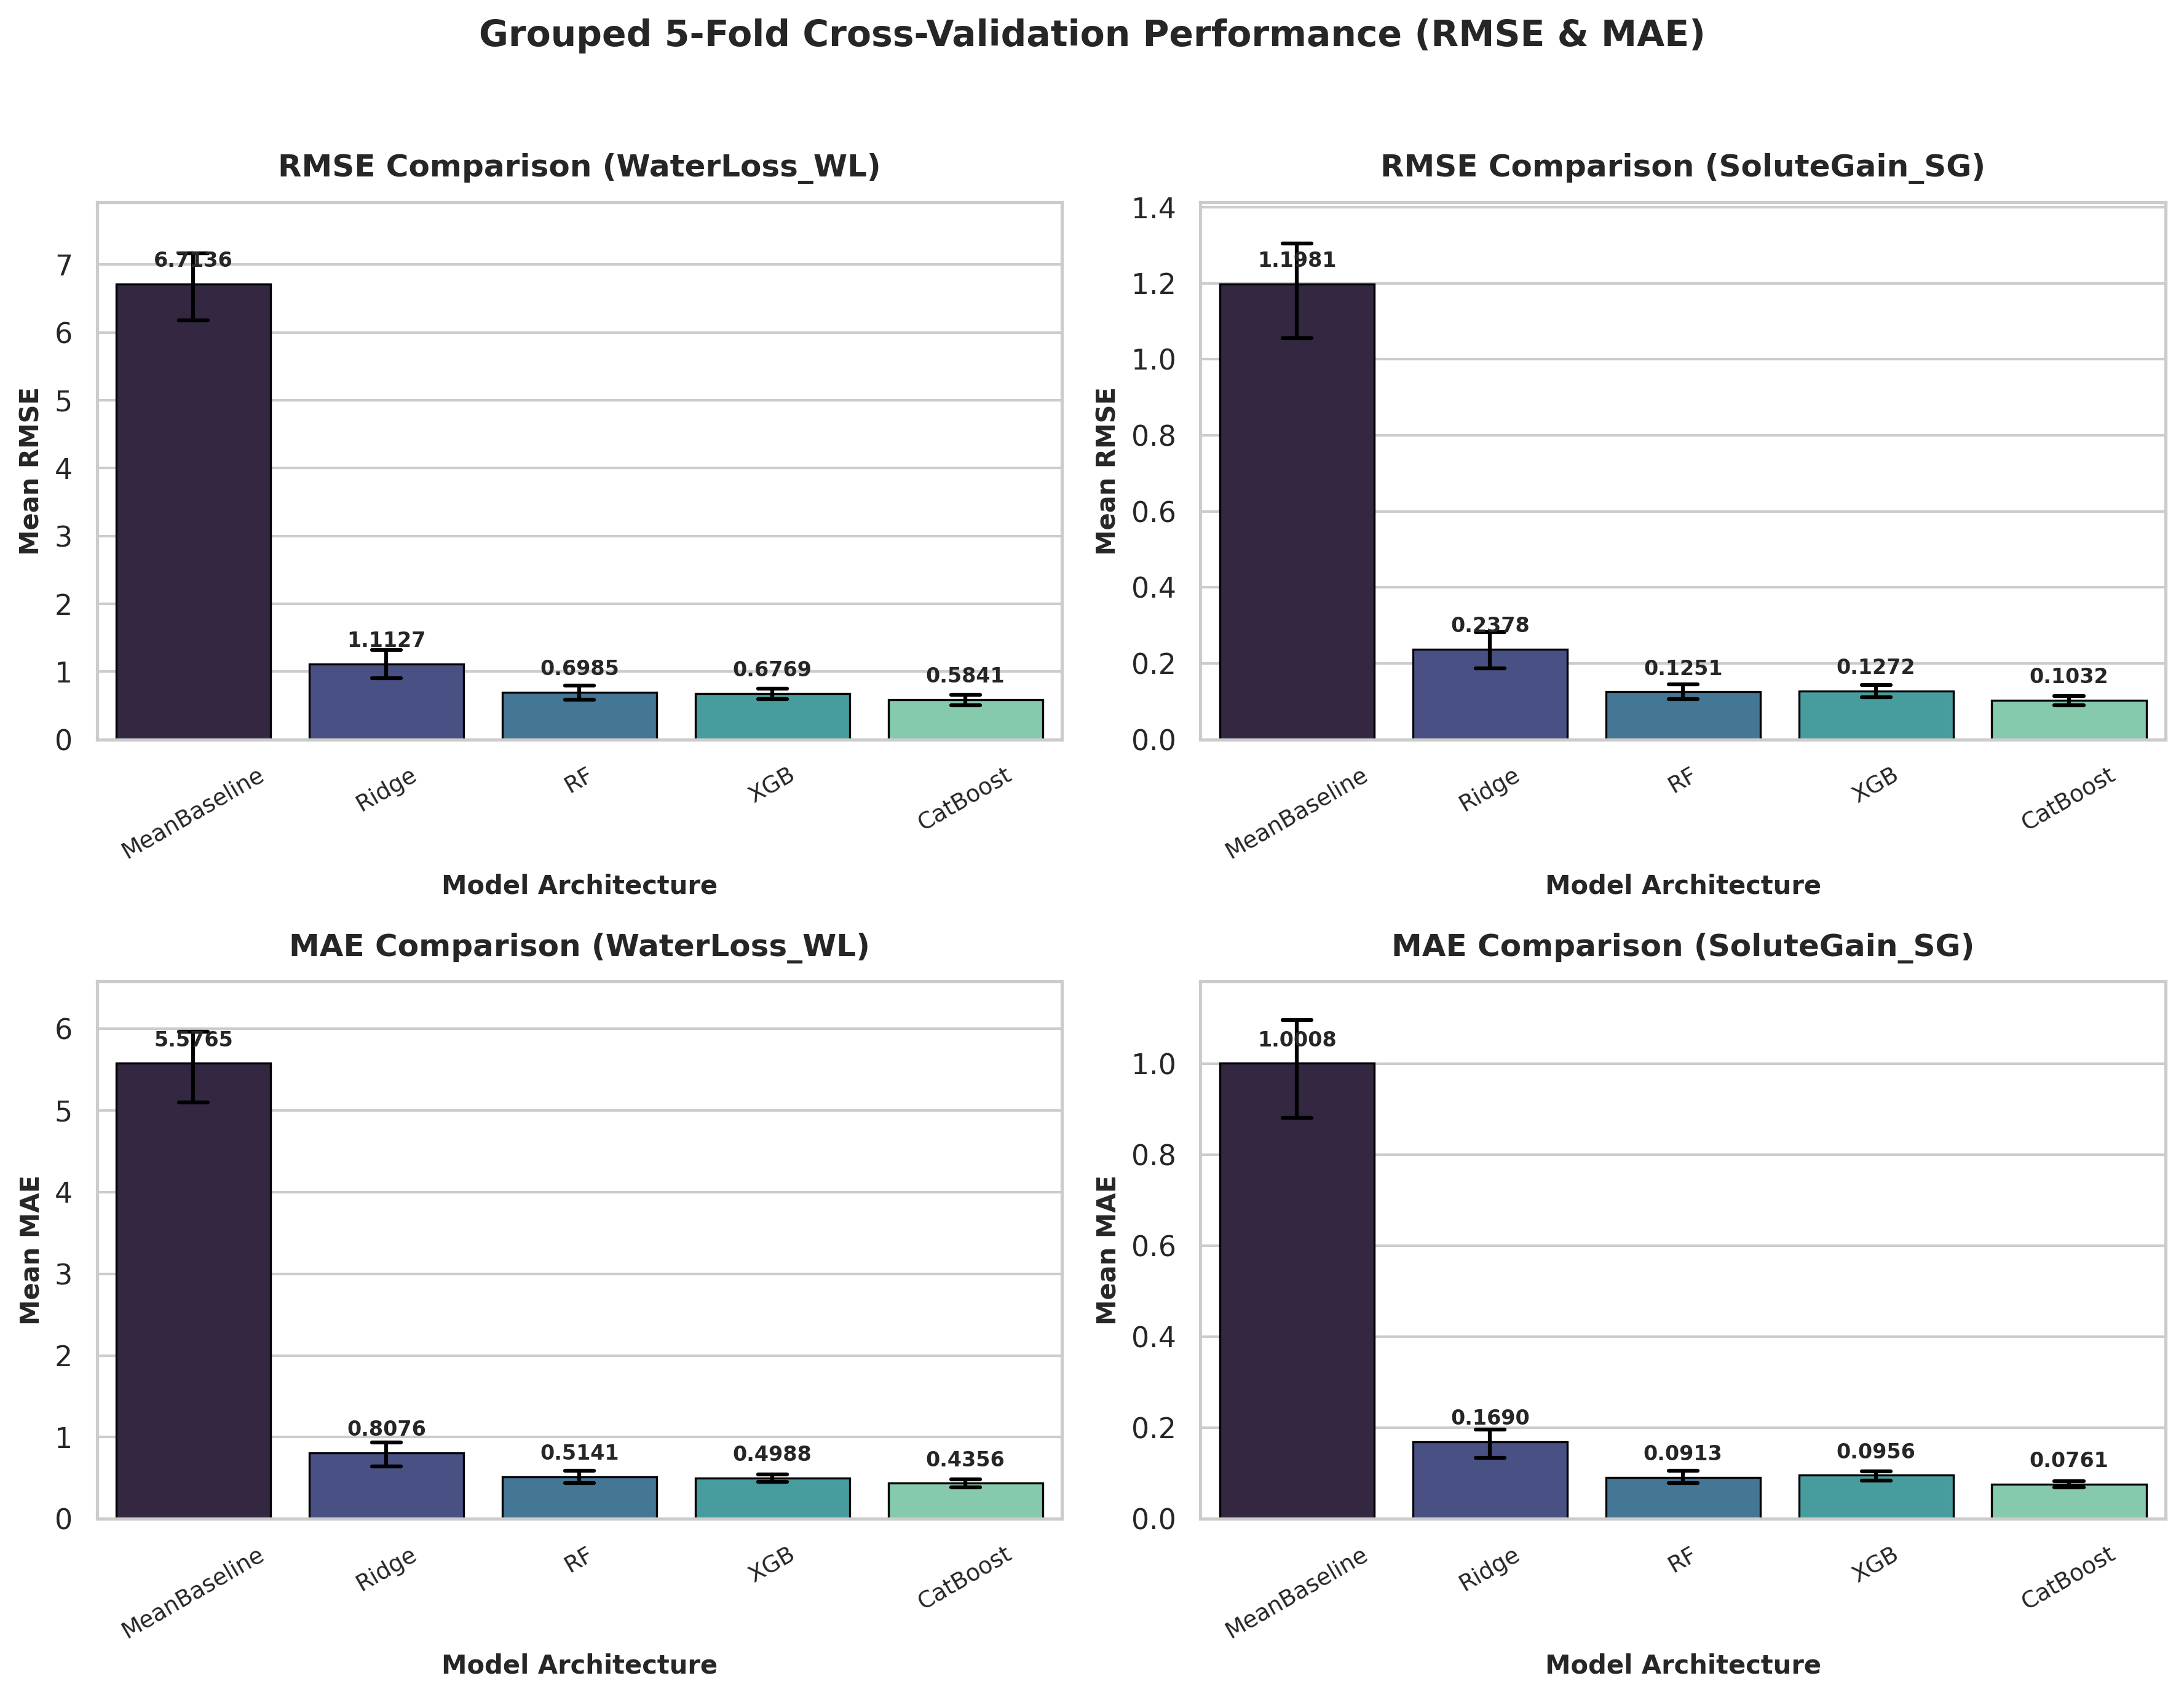

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Plot Style Setup
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.family": "sans-serif"})

targets = cv_results["Target"].unique()
metrics = ["RMSE", "MAE"]
num_targets = len(targets)

fig, axes = plt.subplots(
    nrows=2,
    ncols=num_targets,
    figsize=(6 * num_targets, 9),
    dpi=300,
    sharex=False,
)

if num_targets == 1:
    axes = np.array([[axes[0]], [axes[1]]])

palette = sns.color_palette("mako", n_colors=cv_results["Model"].nunique())

for col_idx, target in enumerate(targets):
    target_data = cv_results[cv_results["Target"] == target]

    for row_idx, metric in enumerate(metrics):
        ax = axes[row_idx, col_idx]
        sns.barplot(
            data=target_data,
            x="Model",
            y=metric,
            ax=ax,
            palette=palette,
            capsize=0.15,
            err_kws={"linewidth": 1.5, "color": "black"},
            edgecolor="black",
            linewidth=0.8,
        )

        ax.set_title(
            f"{metric} Comparison ({target})", fontsize=12, fontweight="bold", pad=10
        )
        ax.set_xlabel("Model Architecture", fontsize=10, fontweight="bold")
        ax.set_ylabel(f"Mean {metric}", fontsize=10, fontweight="bold")
        ax.tick_params(axis="x", rotation=30, labelsize=9)

        means = target_data.groupby("Model", sort=False)[metric].mean()
        for i, (model_name, mean_val) in enumerate(means.items()):
            ax.annotate(
                f"{mean_val:.4f}",
                xy=(i, mean_val),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                fontweight="bold",
            )

        y_max = target_data.groupby("Model")[metric].mean().max()
        ax.set_ylim(0, y_max * 1.18)

plt.suptitle(
    "Grouped 5-Fold Cross-Validation Performance (RMSE & MAE)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

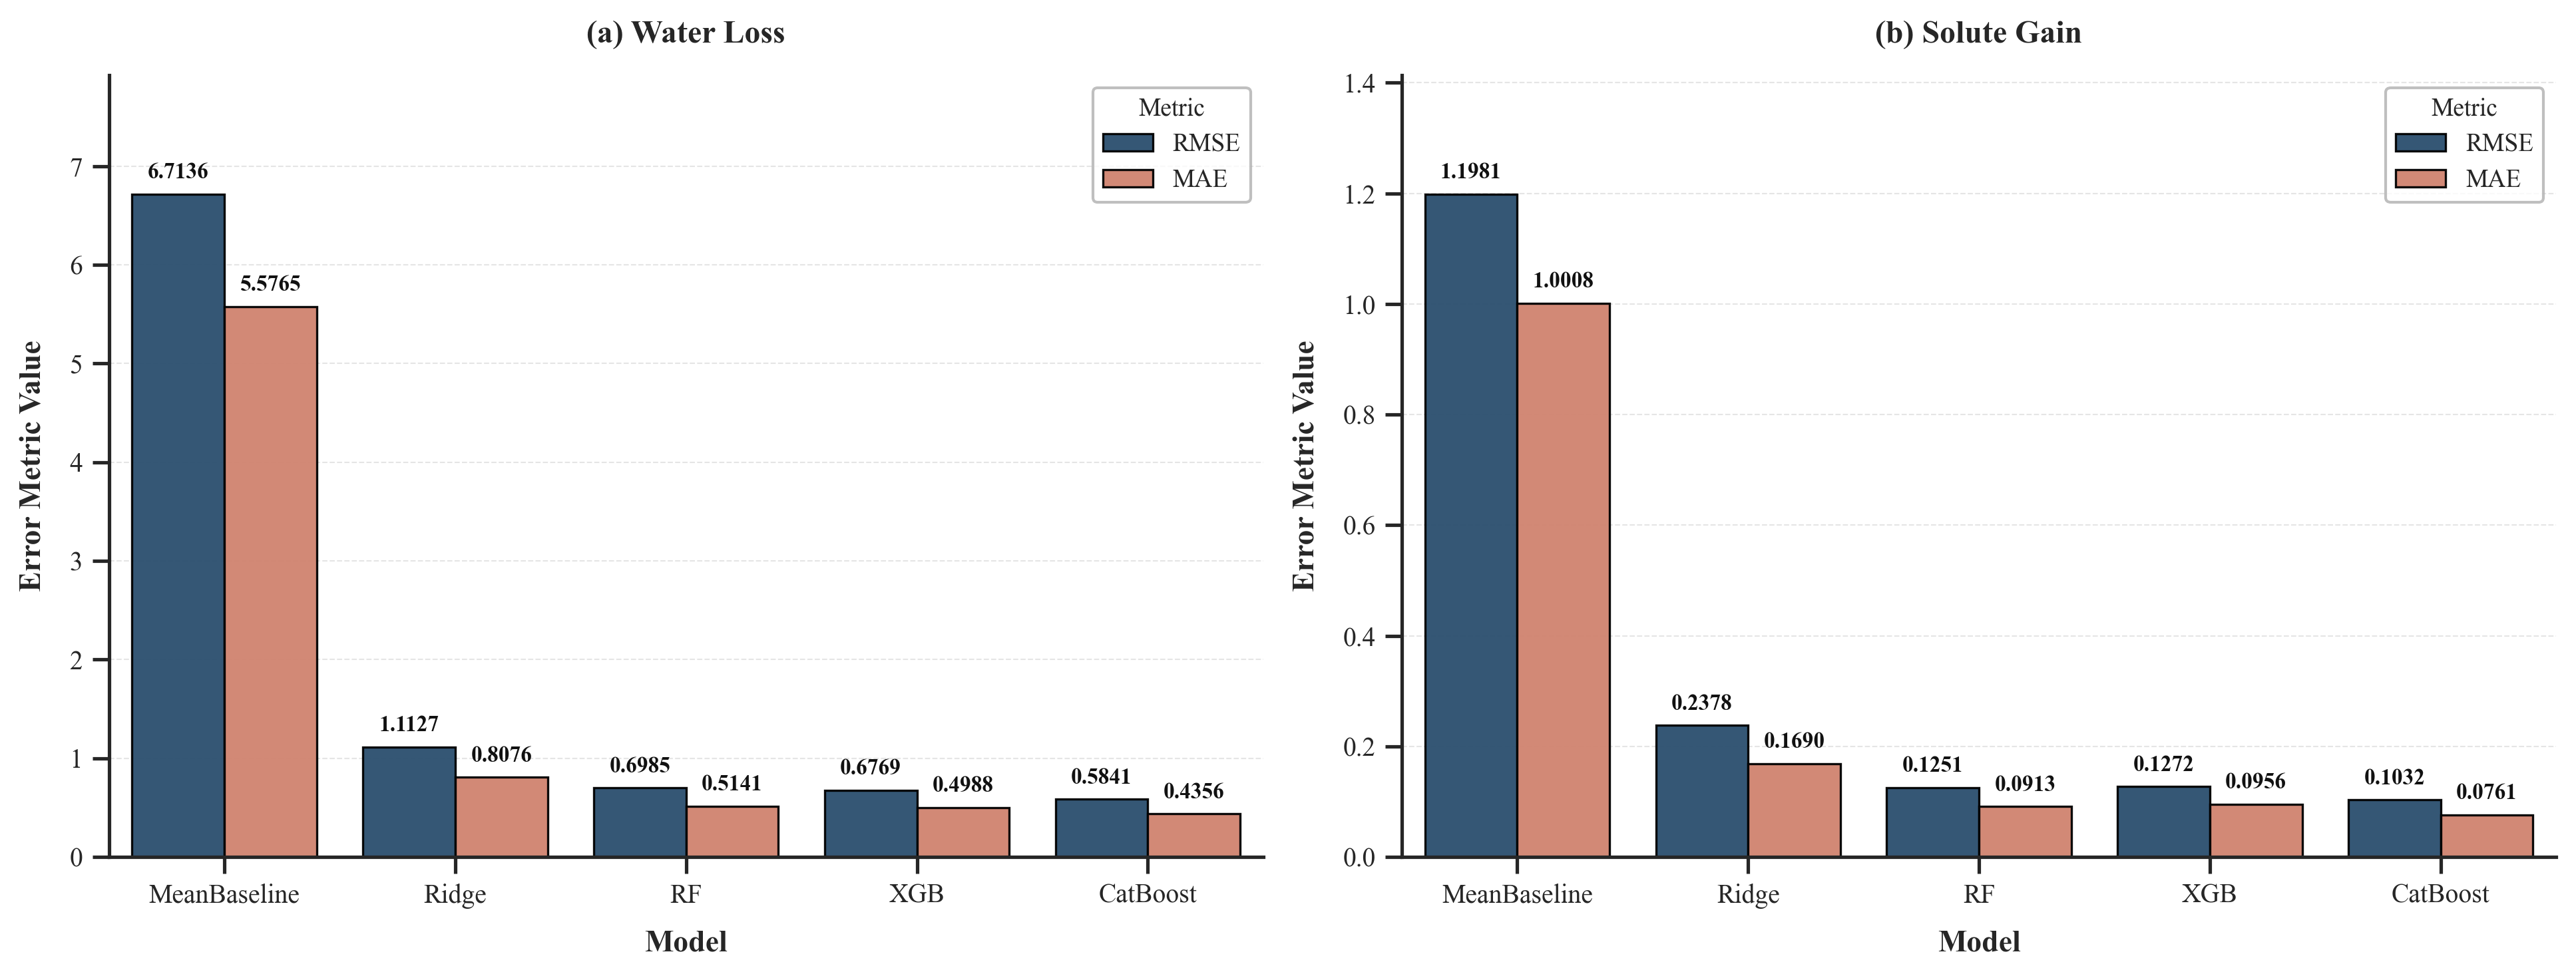

In [39]:

sns.set_theme(
    style="ticks",
    rc={
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
    },
)

cv_melted = cv_results.melt(
    id_vars=["Model", "Target", "Fold"],
    value_vars=["RMSE", "MAE"],
    var_name="Metric",
    value_name="Score",
)

targets = cv_results["Target"].unique()
num_targets = len(targets)

fig, axes = plt.subplots(
    nrows=1, ncols=num_targets, figsize=(6.5 * num_targets, 5.0), dpi=300
)

if num_targets == 1:
    axes = [axes]


metric_palette = {"RMSE": "#1F4E79", "MAE": "#E07A5F"}

for col_idx, target in enumerate(targets):
    ax = axes[col_idx]
    sub_df = cv_melted[cv_melted["Target"] == target]

    # Clean Grouped Bar Plot without error bars
    barplot = sns.barplot(
        data=sub_df,
        x="Model",
        y="Score",
        hue="Metric",
        ax=ax,
        palette=metric_palette,
        errorbar=None,
        edgecolor="black",
        linewidth=0.8,
        alpha=0.95,
    )

    # Annotate exact metric values over bars
    for p in barplot.patches:
        height = p.get_height()
        if np.isnan(height) or height == 0:
            continue
        ax.annotate(
            f"{height:.4f}",
            xy=(p.get_x() + p.get_width() / 2.0, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
            color="#111111",
        )

    target_clean = str(target).lower()
    if "wl" in target_clean or "water" in target_clean:
        target_display = "Water Loss"
    elif "sg" in target_clean or "solute" in target_clean:
        target_display = "Solute Gain"
    else:
        target_display = str(target)

    panel_letter = string.ascii_lowercase[col_idx]
    ax.set_title(f"({panel_letter}) {target_display}", fontweight="bold", pad=12)

    ax.set_xlabel("Model", fontweight="bold", labelpad=8)
    ax.set_ylabel("Error Metric Value", fontweight="bold", labelpad=8)

    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5, color="#CCCCCC")
    ax.set_axisbelow(True)

    y_max = sub_df.groupby(["Model", "Metric"])["Score"].mean().max()
    ax.set_ylim(0, y_max * 1.18)

    ax.legend(
        title="Metric",
        title_fontsize="9",
        fontsize="9",
        frameon=True,
        facecolor="#FFFFFF",
        edgecolor="#B0B0B0",
        loc="upper right",
    )

sns.despine(fig=fig, top=True, right=True)

plt.tight_layout()
plt.savefig("Metrics.png", dpi=600, bbox_inches="tight")
plt.show()

In [9]:
# step-6: Selecting the best surrogate for each CFD response

cv_mean = (
    cv_results
    .groupby(["Model", "Target"])["RMSE"]
    .mean()
    .reset_index()
)

best_models = {}
final_models = {}

for target in TARGETS:
    ranking = (
        cv_mean[cv_mean["Target"] == target]
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    best_name = ranking.loc[0, "Model"]
    best_models[target] = best_name

    model = clone(tuned_models[(target, best_name)])
    model.fit(train_df[FEATURES], train_df[target].to_numpy())

    final_models[target] = model

    print(
        f"{target}: best surrogate = {best_name} "
        f"(grouped-CV RMSE = {ranking.loc[0, 'RMSE']:.5f})"
    )


WaterLoss_WL: best surrogate = CatBoost (grouped-CV RMSE = 0.58411)
SoluteGain_SG: best surrogate = CatBoost (grouped-CV RMSE = 0.10318)


In [10]:
# step-7: Final evaluation on completely unseen CFD/simulation runs

pred_df = test_df[[RUN_COL, TIME_COL] + TARGETS].copy()
external_rows = []

for target in TARGETS:
    model = final_models[target]

    y_true = test_df[target].to_numpy()
    y_pred = model.predict(test_df[FEATURES])

    pred_df[f"{target}_pred"] = y_pred

    external_rows.append({
        "Target": target,
        "SelectedModel": best_models[target],
        "TestType": "Unseen simulation runs",
        **regression_metrics(y_true, y_pred),
    })

external_results = pd.DataFrame(external_rows).round(5)

print("=" * 60)
print("FINAL UNSEEN-RUN TEST")
print("=" * 60)
display(external_results)


FINAL UNSEEN-RUN TEST


,Target,SelectedModel,TestType,RMSE,MAE,R2
0,WaterLoss_WL,CatBoost,Unseen simulation runs,0.47722,0.36200,0.99429
1,SoluteGain_SG,CatBoost,Unseen simulation runs,0.10280,0.07481,0.99128


In [11]:
# step-8: Run-level robustness

run_rows = []

for target in TARGETS:
    pred_col = f"{target}_pred"

    for run_id, g in pred_df.groupby(RUN_COL):
        m = regression_metrics(g[target], g[pred_col])

        run_rows.append({
            "Target": target,
            "Run_ID": run_id,
            **m,
        })

run_results = pd.DataFrame(run_rows)

run_summary = (
    run_results.groupby("Target")[["RMSE", "MAE", "R2"]]
    .agg(["mean", "std", "min", "max"])
    .round(5)
)

display(run_summary)


RMSE                                 MAE                    \
                  mean      std      min      max     mean      std      min   
Target                                                                         
SoluteGain_SG  0.08286  0.06242  0.01464  0.24466  0.07481  0.06012  0.01079   
WaterLoss_WL   0.40622  0.25694  0.10249  0.99619  0.36200  0.24616  0.08541   

                             R2                             
                   max     mean      std      min      max  
Target                                                      
SoluteGain_SG  0.23268  0.98487  0.01806  0.93459  0.99961  
WaterLoss_WL   0.94095  0.99184  0.00923  0.97003  0.99926

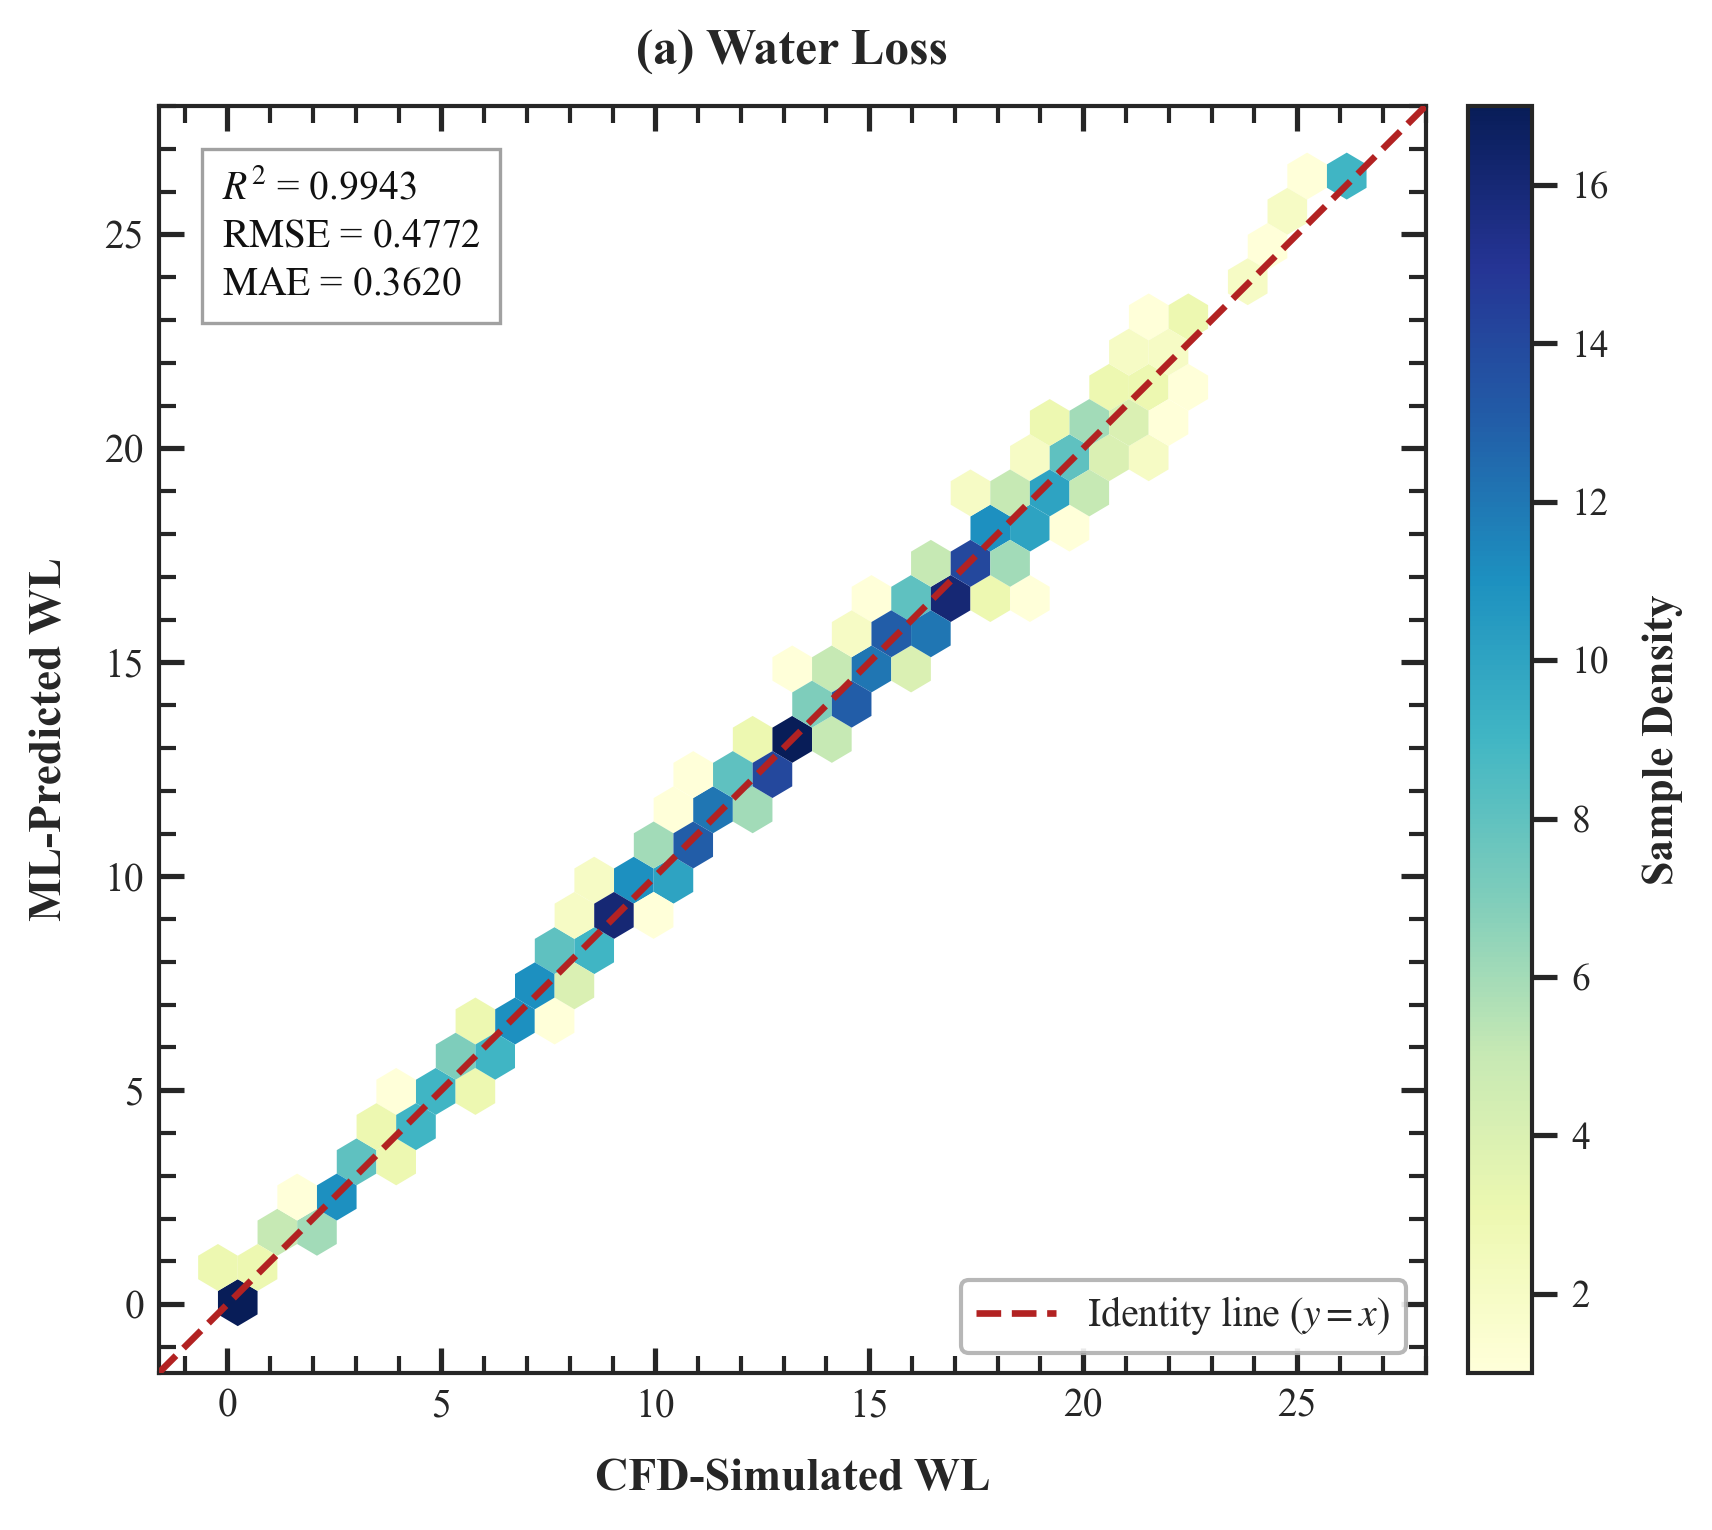

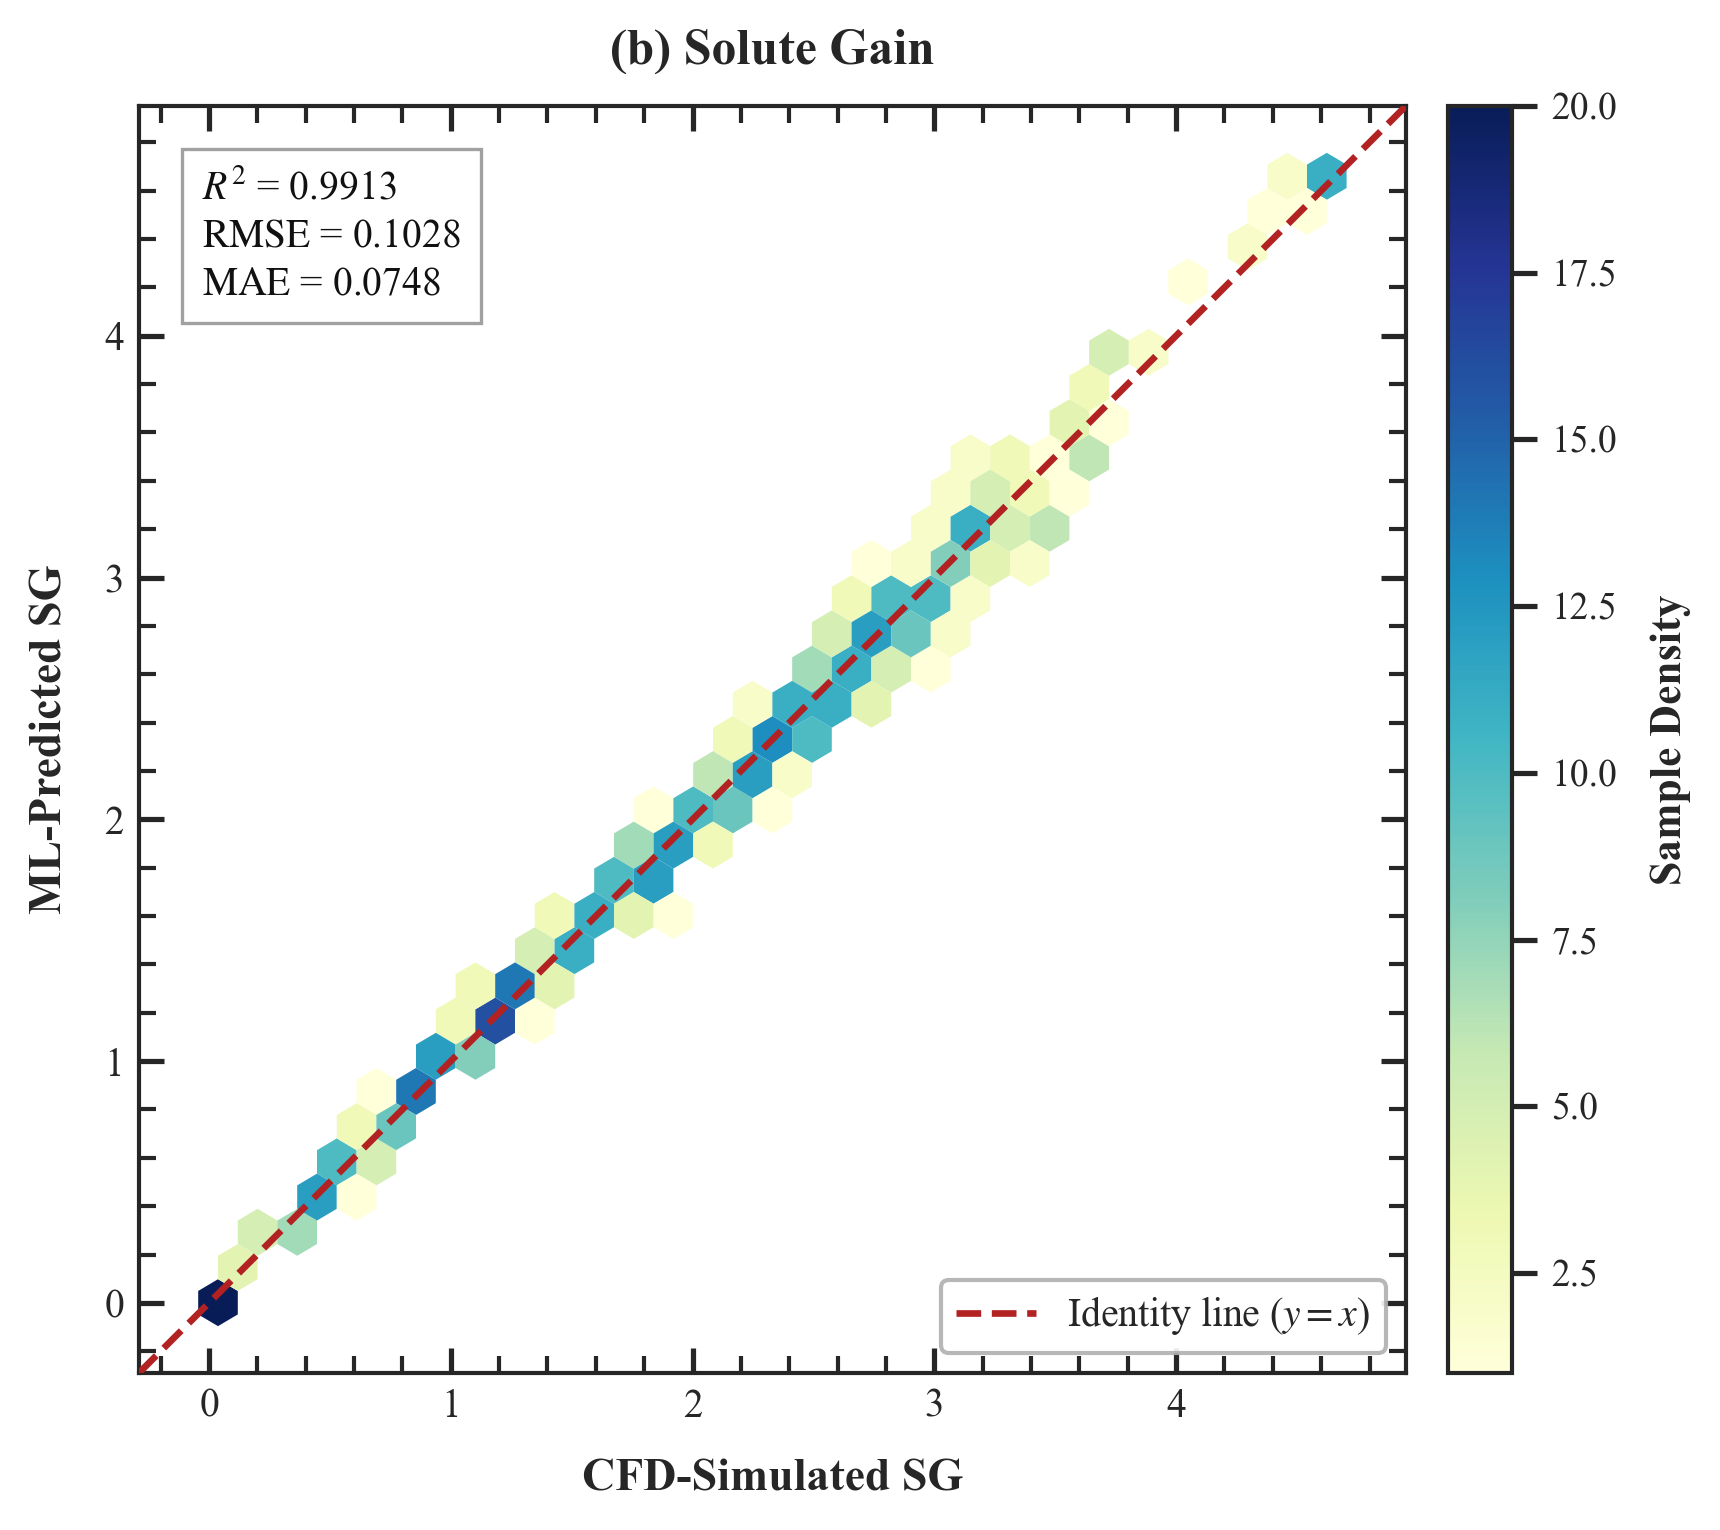

In [40]:
from pathlib import Path
from matplotlib.ticker import AutoMinorLocator

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "axes.linewidth": 1.0,
    }
)

TARGET_CONFIG = {
    "WaterLoss_WL": {
        "title": "Water Loss",
        "label": "WL",
        "panel": "(a)",
    },
    "SoluteGain_SG": {
        "title": "Solute Gain",
        "label": "SG",
        "panel": "(b)",
    },
}


def save_parity_plot(target):
    y_true = pred_df[target].to_numpy()
    y_pred = pred_df[f"{target}_pred"].to_numpy()
    m = regression_metrics(y_true, y_pred)

    cfg = TARGET_CONFIG.get(
        target,
        {
            "title": target,
            "label": target,
            "panel": "",
        },
    )

    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    pad = 0.05 * (hi - lo) if hi != lo else 0.1
    lim_min, lim_max = lo - pad, hi + pad

    fig, ax = plt.subplots(figsize=(5.8, 5.2), dpi=300)

    hb = ax.hexbin(
        y_true,
        y_pred,
        gridsize=32,
        cmap="YlGnBu",
        mincnt=1,
        edgecolors="none",
        extent=[lim_min, lim_max, lim_min, lim_max],
        zorder=2,
    )


    ax.plot(
        [lim_min, lim_max],
        [lim_min, lim_max],
        color="#B22222",  
        linestyle="--",
        linewidth=1.6,
        label="Identity line ($y = x$)",
        zorder=3,
    )

    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_aspect("equal", adjustable="box")


    metrics_text = (
        r"$R^2$" f" = {m['R2']:.4f}\n"
        r"$\mathrm{RMSE}$" f" = {m['RMSE']:.4f}\n"
        r"$\mathrm{MAE}$" f" = {m['MAE']:.4f}"
    )

    ax.text(
        0.05,
        0.95,
        metrics_text,
        transform=ax.transAxes,
        fontsize=9.5,
        verticalalignment="top",
        linespacing=1.35,
        color="#111111",
        bbox=dict(
            boxstyle="square,pad=0.5",
            facecolor="#FFFFFF",
            edgecolor="#999999",
            linewidth=0.8,
            alpha=0.92,
        ),
        zorder=4,
    )

    cbar = fig.colorbar(hb, ax=ax, pad=0.03, fraction=0.046)
    cbar.set_label("Sample Density", fontsize=10.5, fontweight="bold", labelpad=8)
    cbar.ax.tick_params(labelsize=9)

    ax.set_xlabel(
        f"CFD-Simulated {cfg['label']}",
        fontsize=11,
        fontweight="bold",
        labelpad=8,
    )
    ax.set_ylabel(
        f"ML-Predicted {cfg['label']}",
        fontsize=11,
        fontweight="bold",
        labelpad=8,
    )

    # Water Loss
    panel_title = f"{cfg['panel']} {cfg['title']}".strip()
    ax.set_title(panel_title, fontsize=12, fontweight="bold", pad=10)

    ax.tick_params(
        direction="in", which="both", top=True, right=True, labelsize=9.5
    )
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.legend(
        loc="lower right",
        frameon=True,
        facecolor="#FFFFFF",
        edgecolor="#B0B0B0",
        fontsize=9.5,
        framealpha=0.9,
    )
    plt.tight_layout()

    fig_dir = Path(FIG_DIR)
    fig_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        fig_dir / f"parity_density_{target}.png",
        dpi=600,
        bbox_inches="tight",
    )
    fig.savefig(
        fig_dir / f"parity_density_{target}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)



for target in TARGETS:
    save_parity_plot(target)

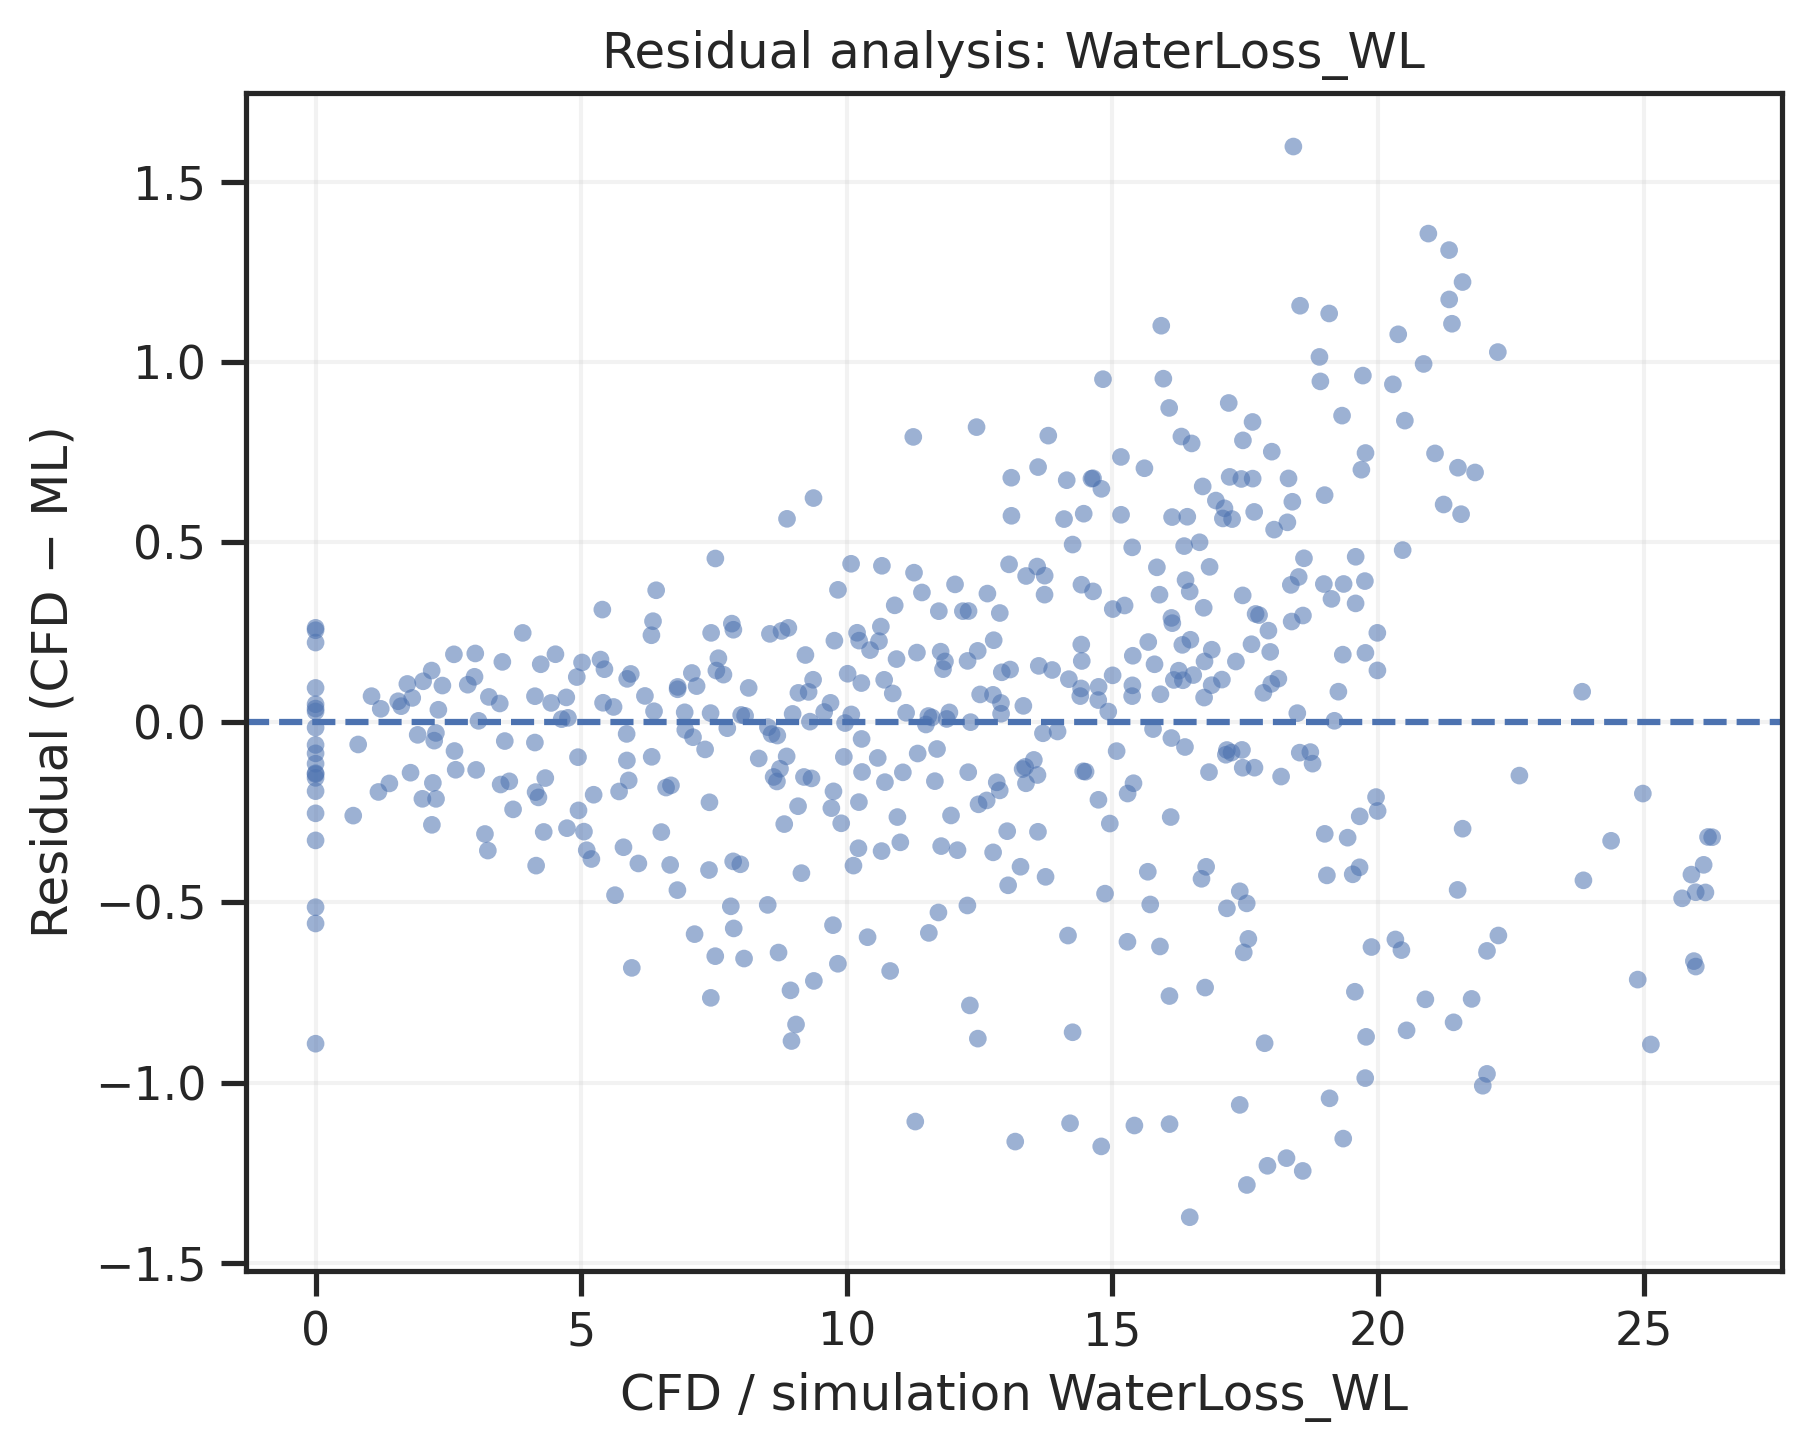

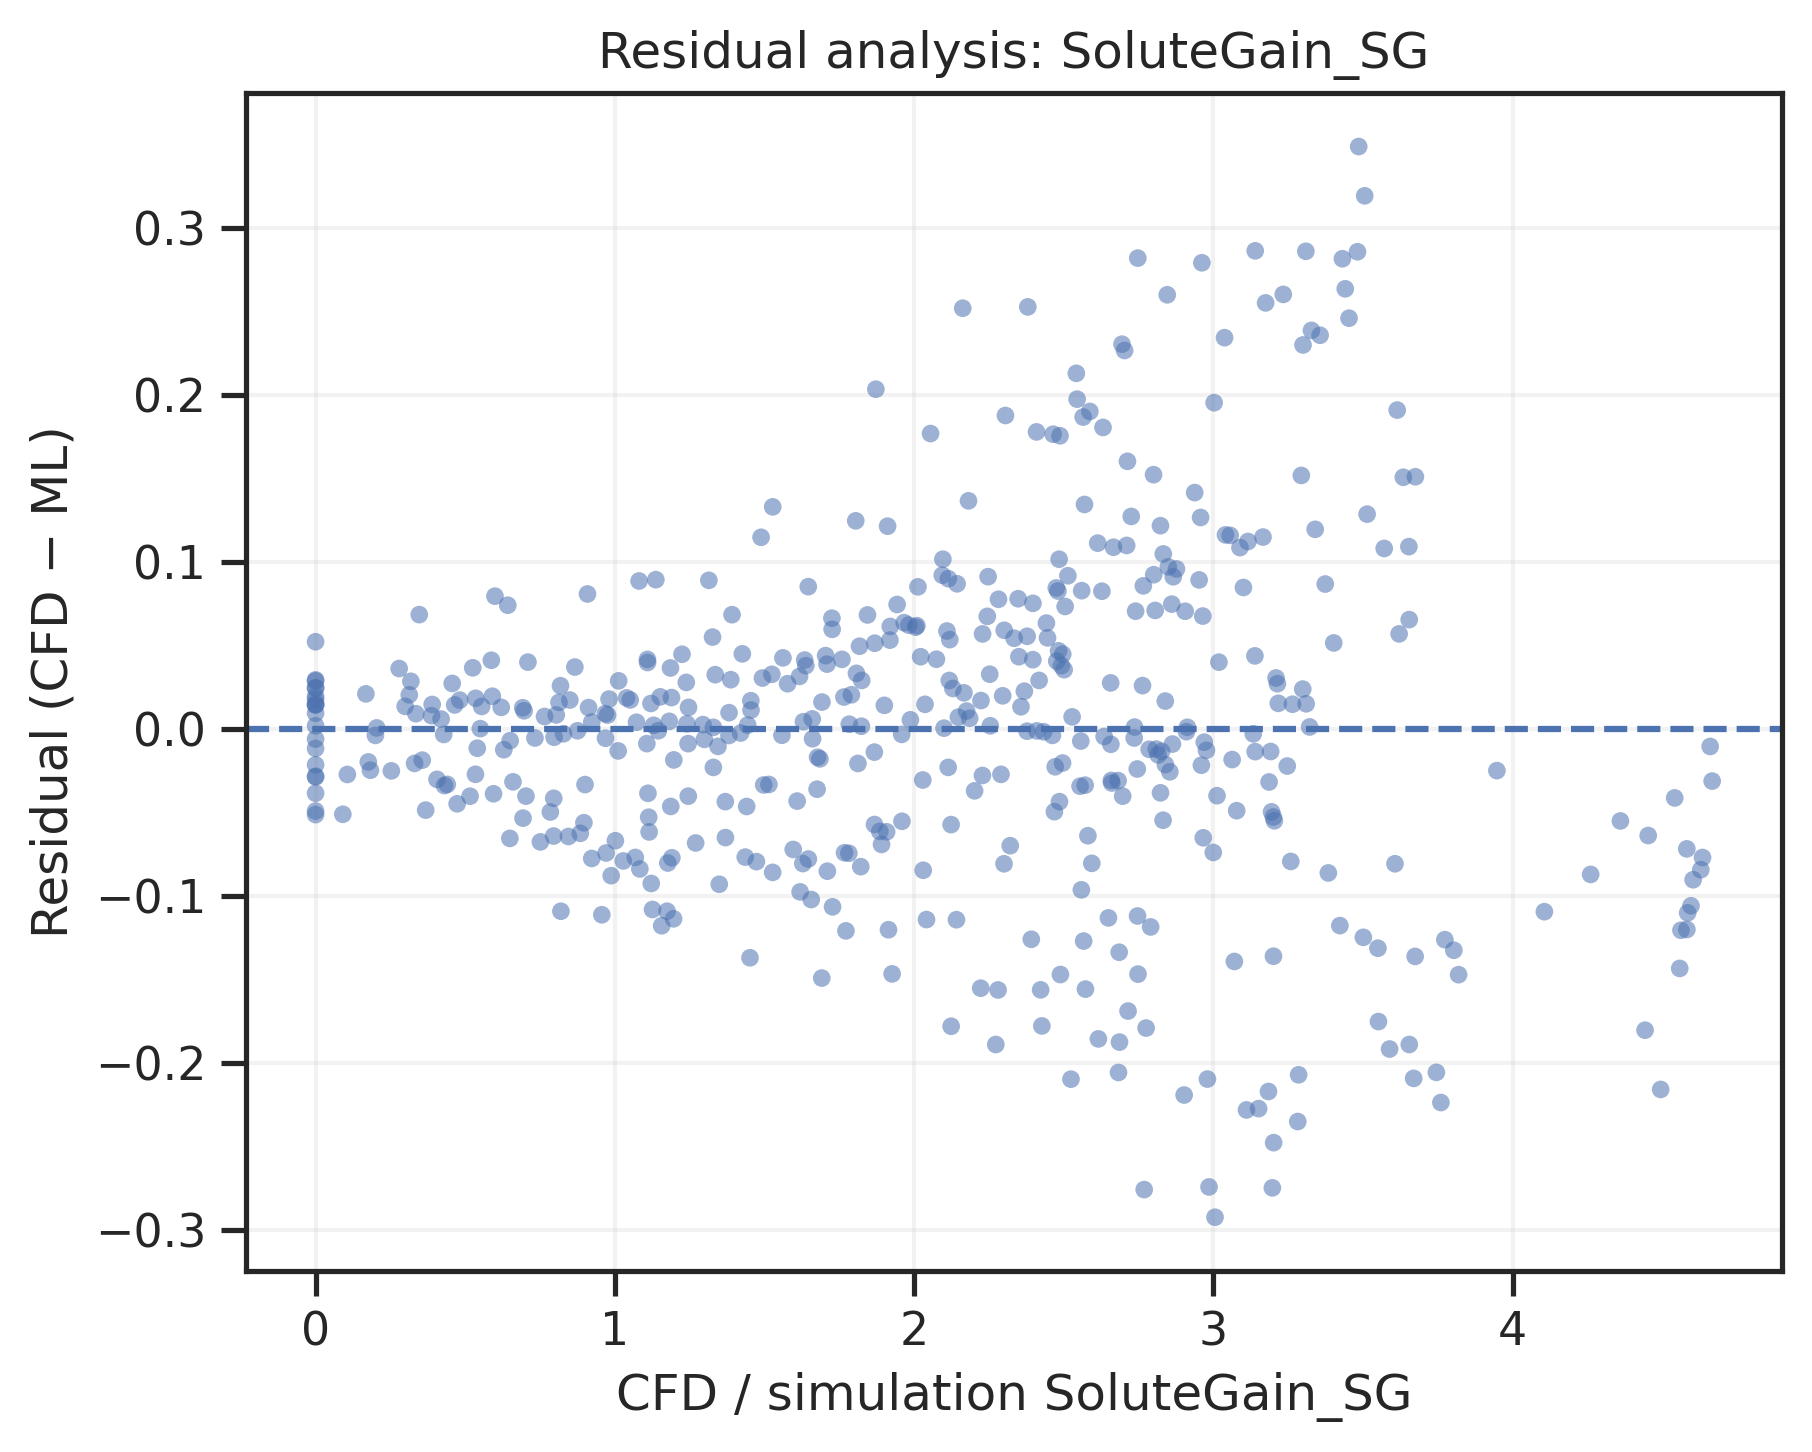

In [13]:
# step-10: Publication figure: residual analysis

def save_residual_plot(target):
    y_true = pred_df[target].to_numpy()
    y_pred = pred_df[f"{target}_pred"].to_numpy()
    residual = y_true - y_pred

    fig, ax = plt.subplots(figsize=(6.2, 5.0), dpi=300)

    ax.scatter(
        y_true, residual,
        s=18, alpha=0.55,
        edgecolors="none"
    )
    ax.axhline(0, linestyle="--", linewidth=1.5)

    ax.set_xlabel(f"CFD / simulation {target}")
    ax.set_ylabel("Residual (CFD − ML)")
    ax.set_title(f"Residual analysis: {target}")

    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        FIG_DIR / f"residual_{target}.png",
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


for target in TARGETS:
    save_residual_plot(target)


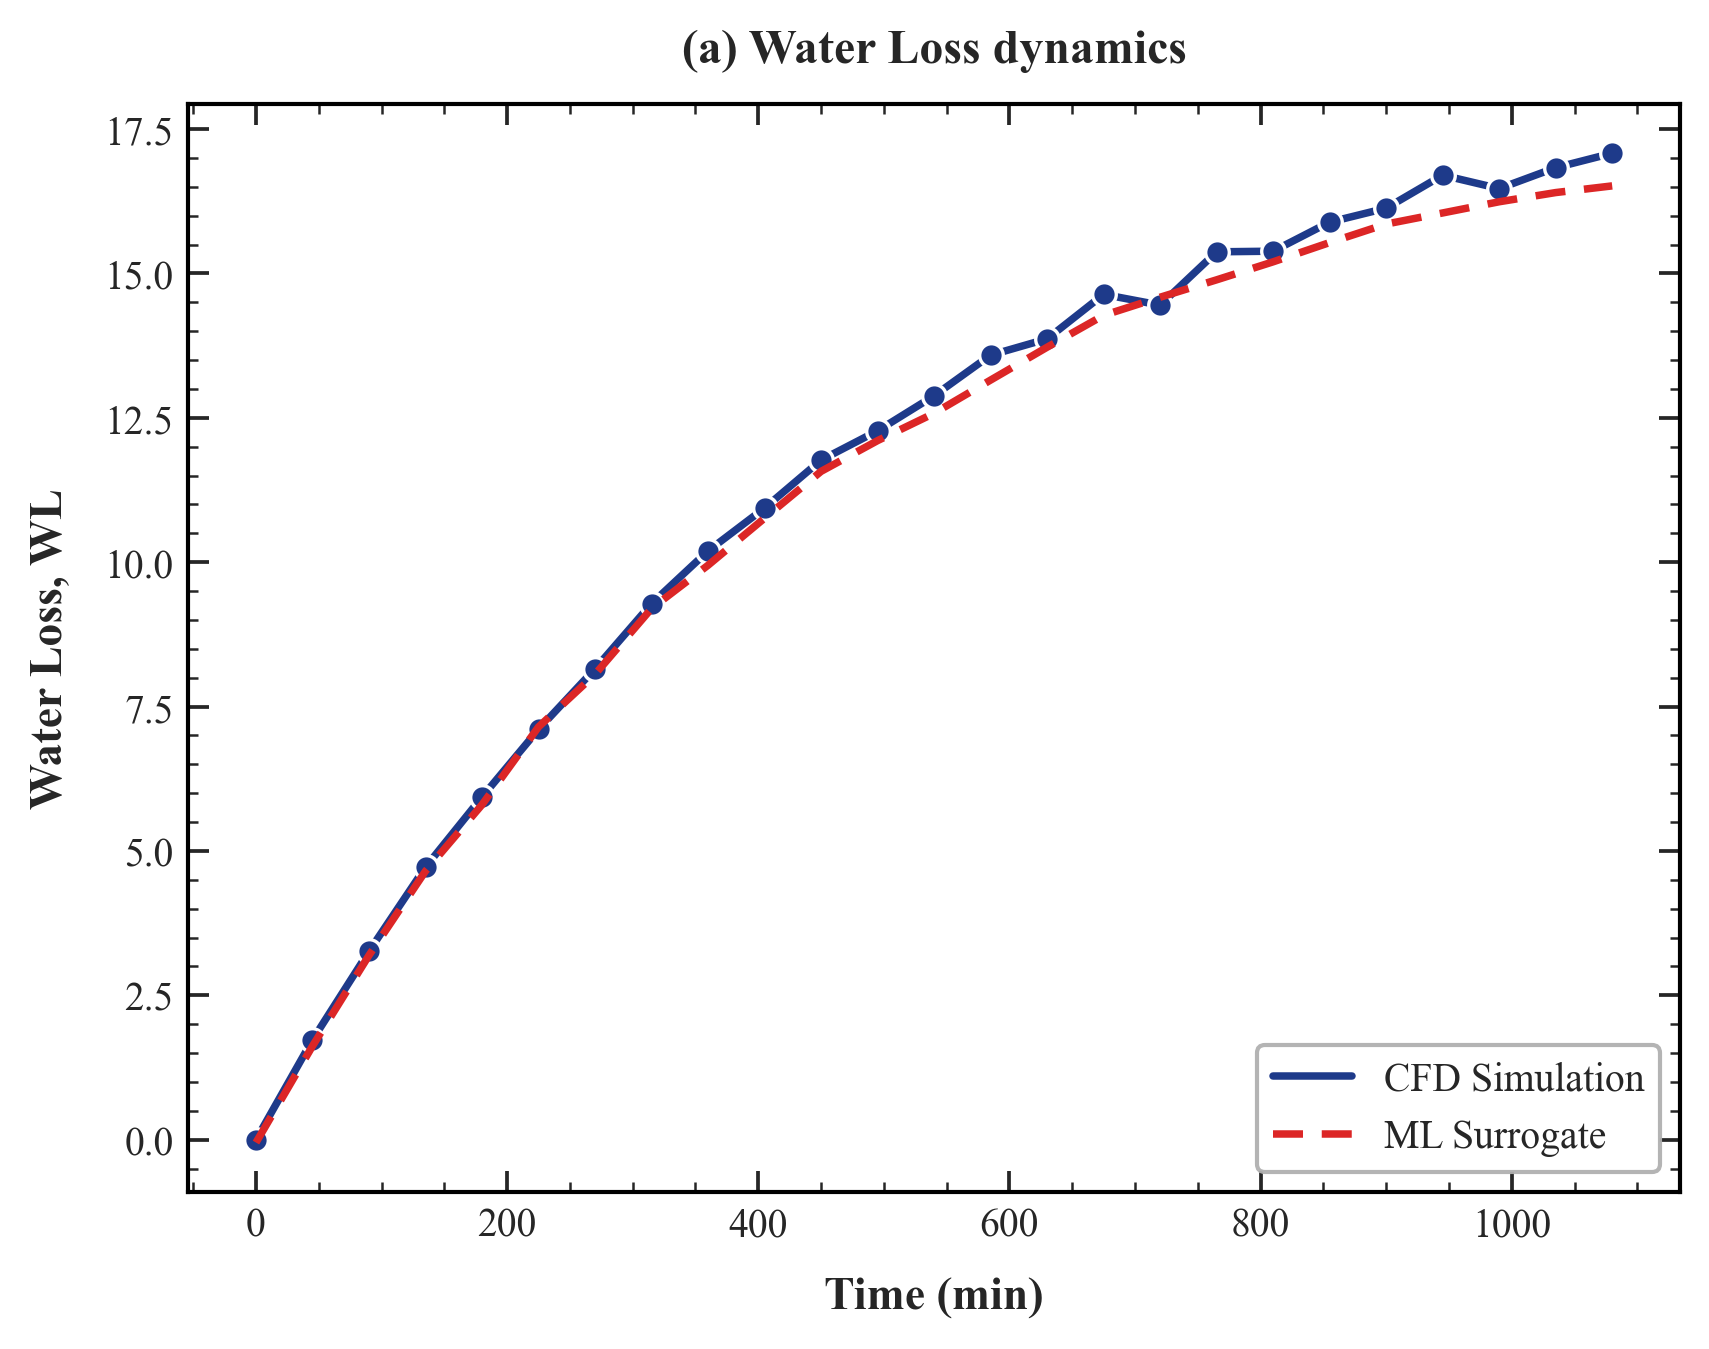

Saved: unseen_run_trajectory_WaterLoss_WL.png & unseen_run_trajectory_WaterLoss_WL.pdf


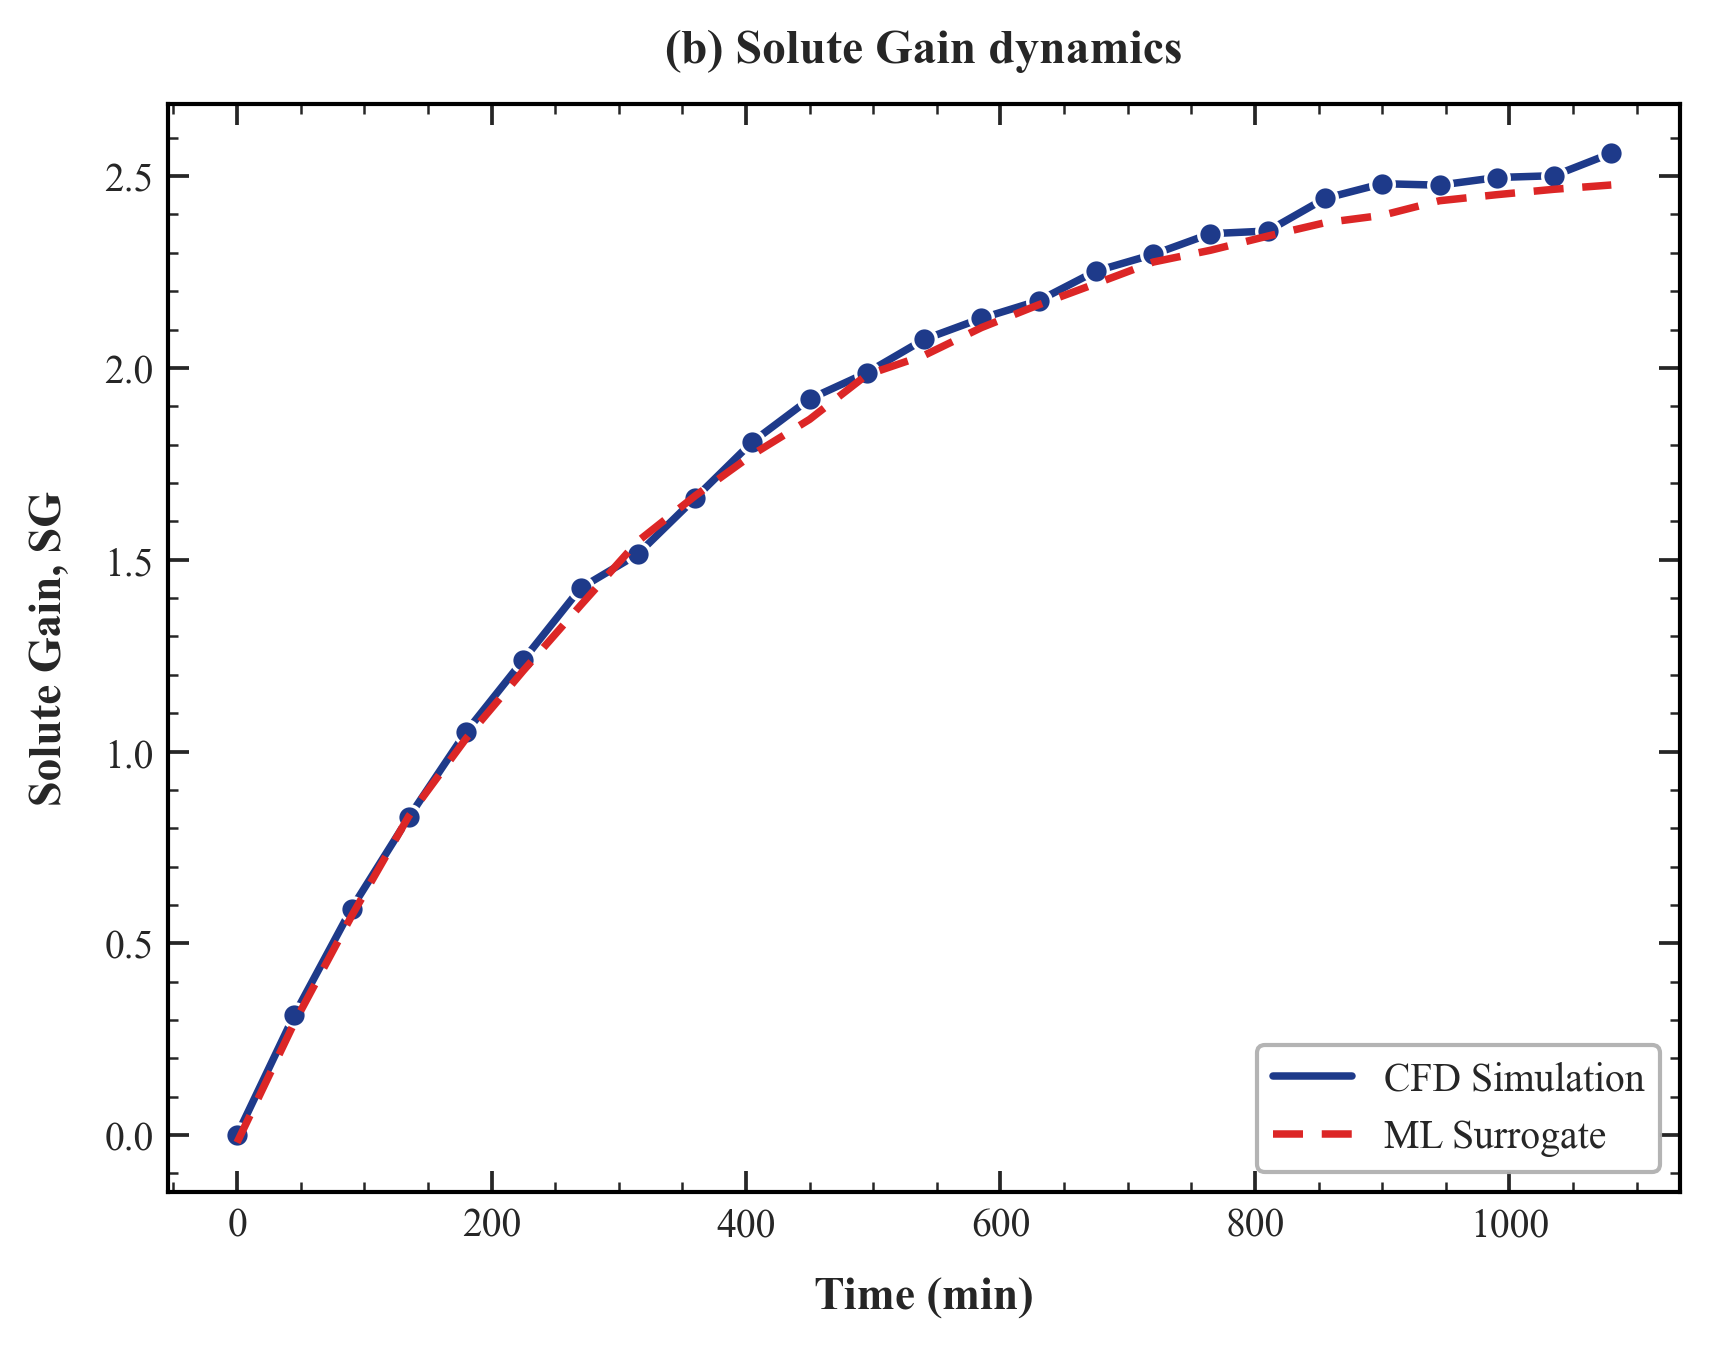

Saved: unseen_run_trajectory_SoluteGain_SG.png & unseen_run_trajectory_SoluteGain_SG.pdf

Plotted Trajectories for Unseen Run_ID: 3


In [41]:


plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "axes.linewidth": 1.0,
    }
)

RUN_COL = "Run_ID"
TIME_COL = "Time_min"
TARGETS = ["WaterLoss_WL", "SoluteGain_SG"]

TARGET_CONFIG = {
    "WaterLoss_WL": {
        "panel": "(a)",
        "title": "Water Loss dynamics",
        "ylabel": "Water Loss, WL",
    },
    "SoluteGain_SG": {
        "panel": "(b)",
        "title": "Solute Gain dynamics",
        "ylabel": "Solute Gain, SG",
    },
}

representative_run = test_df[RUN_COL].unique()[0]
traj = pred_df[pred_df[RUN_COL] == representative_run].sort_values(TIME_COL)

fig_dir = Path(FIG_DIR)
fig_dir.mkdir(parents=True, exist_ok=True)

# Plotting Trajectories
for target in TARGETS:
    cfg = TARGET_CONFIG.get(
        target,
        {
            "panel": "",
            "title": target,
            "ylabel": target,
        },
    )

    fig, ax = plt.subplots(figsize=(5.8, 4.6), dpi=300)
    ax.plot(
        traj[TIME_COL],
        traj[target],
        color="#1E3A8A",
        linewidth=1.8,
        label="CFD Simulation",
        zorder=2,
    )
    ax.scatter(
        traj[TIME_COL],
        traj[target],
        s=32,
        color="#1E3A8A",
        edgecolors="white",
        linewidths=0.8,
        zorder=3,
    )

    ax.plot(
        traj[TIME_COL],
        traj[f"{target}_pred"],
        color="#DC2626",
        linestyle=(0, (4, 2.5)),
        linewidth=1.8,
        label="ML Surrogate",
        zorder=4,
    )

    ax.set_xlabel("Time (min)", fontsize=11, fontweight="bold", labelpad=8)
    ax.set_ylabel(cfg["ylabel"], fontsize=11, fontweight="bold", labelpad=8)

    panel_title = f"{cfg['panel']} {cfg['title']}".strip()
    ax.set_title(panel_title, fontsize=11.5, fontweight="bold", pad=10)

    ax.tick_params(
        direction="in",
        which="major",
        top=True,
        right=True,
        length=5.0,
        width=0.9,
        labelsize=9.5,
    )
    ax.tick_params(
        direction="in",
        which="minor",
        top=True,
        right=True,
        length=2.5,
        width=0.6,
    )
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)

    ax.legend(
        loc="lower right",
        frameon=True,
        facecolor="#FFFFFF",
        edgecolor="#B0B0B0",
        fontsize=9.5,
        framealpha=0.95,
    )

    plt.tight_layout()

    save_png = fig_dir / f"unseen_run_trajectory_{target}.png"
    save_pdf = fig_dir / f"unseen_run_trajectory_{target}.pdf"

    fig.savefig(save_png, dpi=600, bbox_inches="tight")
    fig.savefig(save_pdf, format="pdf", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Saved: {save_png.name} & {save_pdf.name}")

print(f"\nPlotted Trajectories for Unseen Run_ID: {representative_run}")

In [45]:
representative_run = test_df[RUN_COL].unique()[0]
representative_run

np.int64(3)

In [51]:
test_df[test_df[RUN_COL] == representative_run][["Temperature_C", "Brix"]]

,Temperature_C,Brix
50,51.959818,5
51,51.959818,5
52,51.959818,5
53,51.959818,5
54,51.959818,5
55,51.959818,5
56,51.959818,5
57,51.959818,5
58,51.959818,5
59,51.959818,5


In [48]:
df.columns

Index(['Run_ID', 'Temperature_C', 'Brix', 'SpecificGravity', 'Time_min',
       'WaterLoss_WL', 'SoluteGain_SG'],
      dtype='object')

In [1]:

# temp_val = traj["Temperature_C"].iloc[0]
# brix_val = traj["Brix"].iloc[0]

# print(f"Constant Temperature: {temp_val} °C")
# print(f"Constant Brix: {brix_val} °Brix")


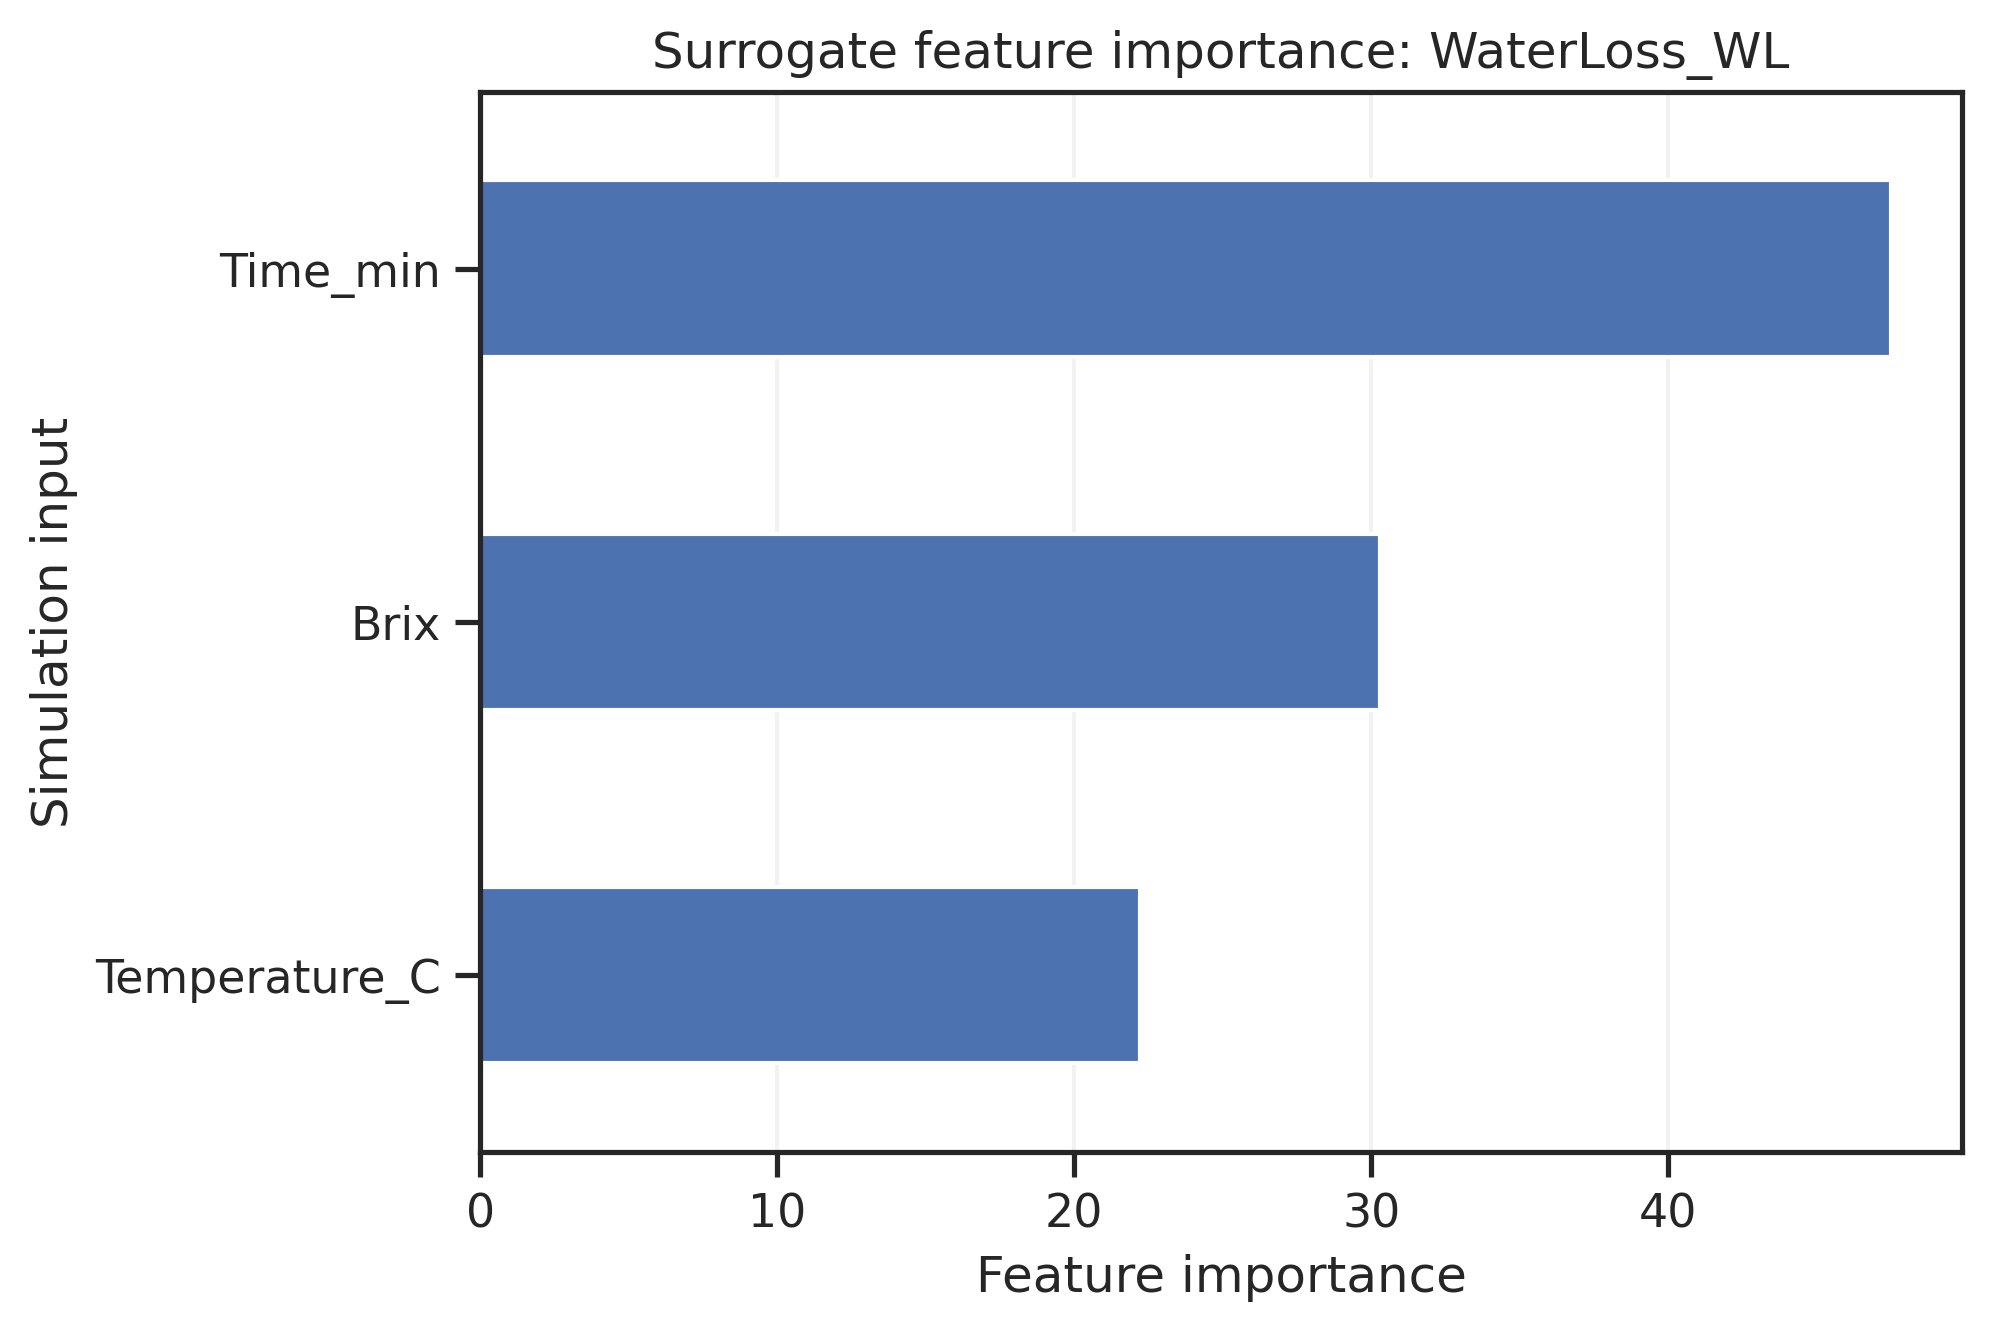

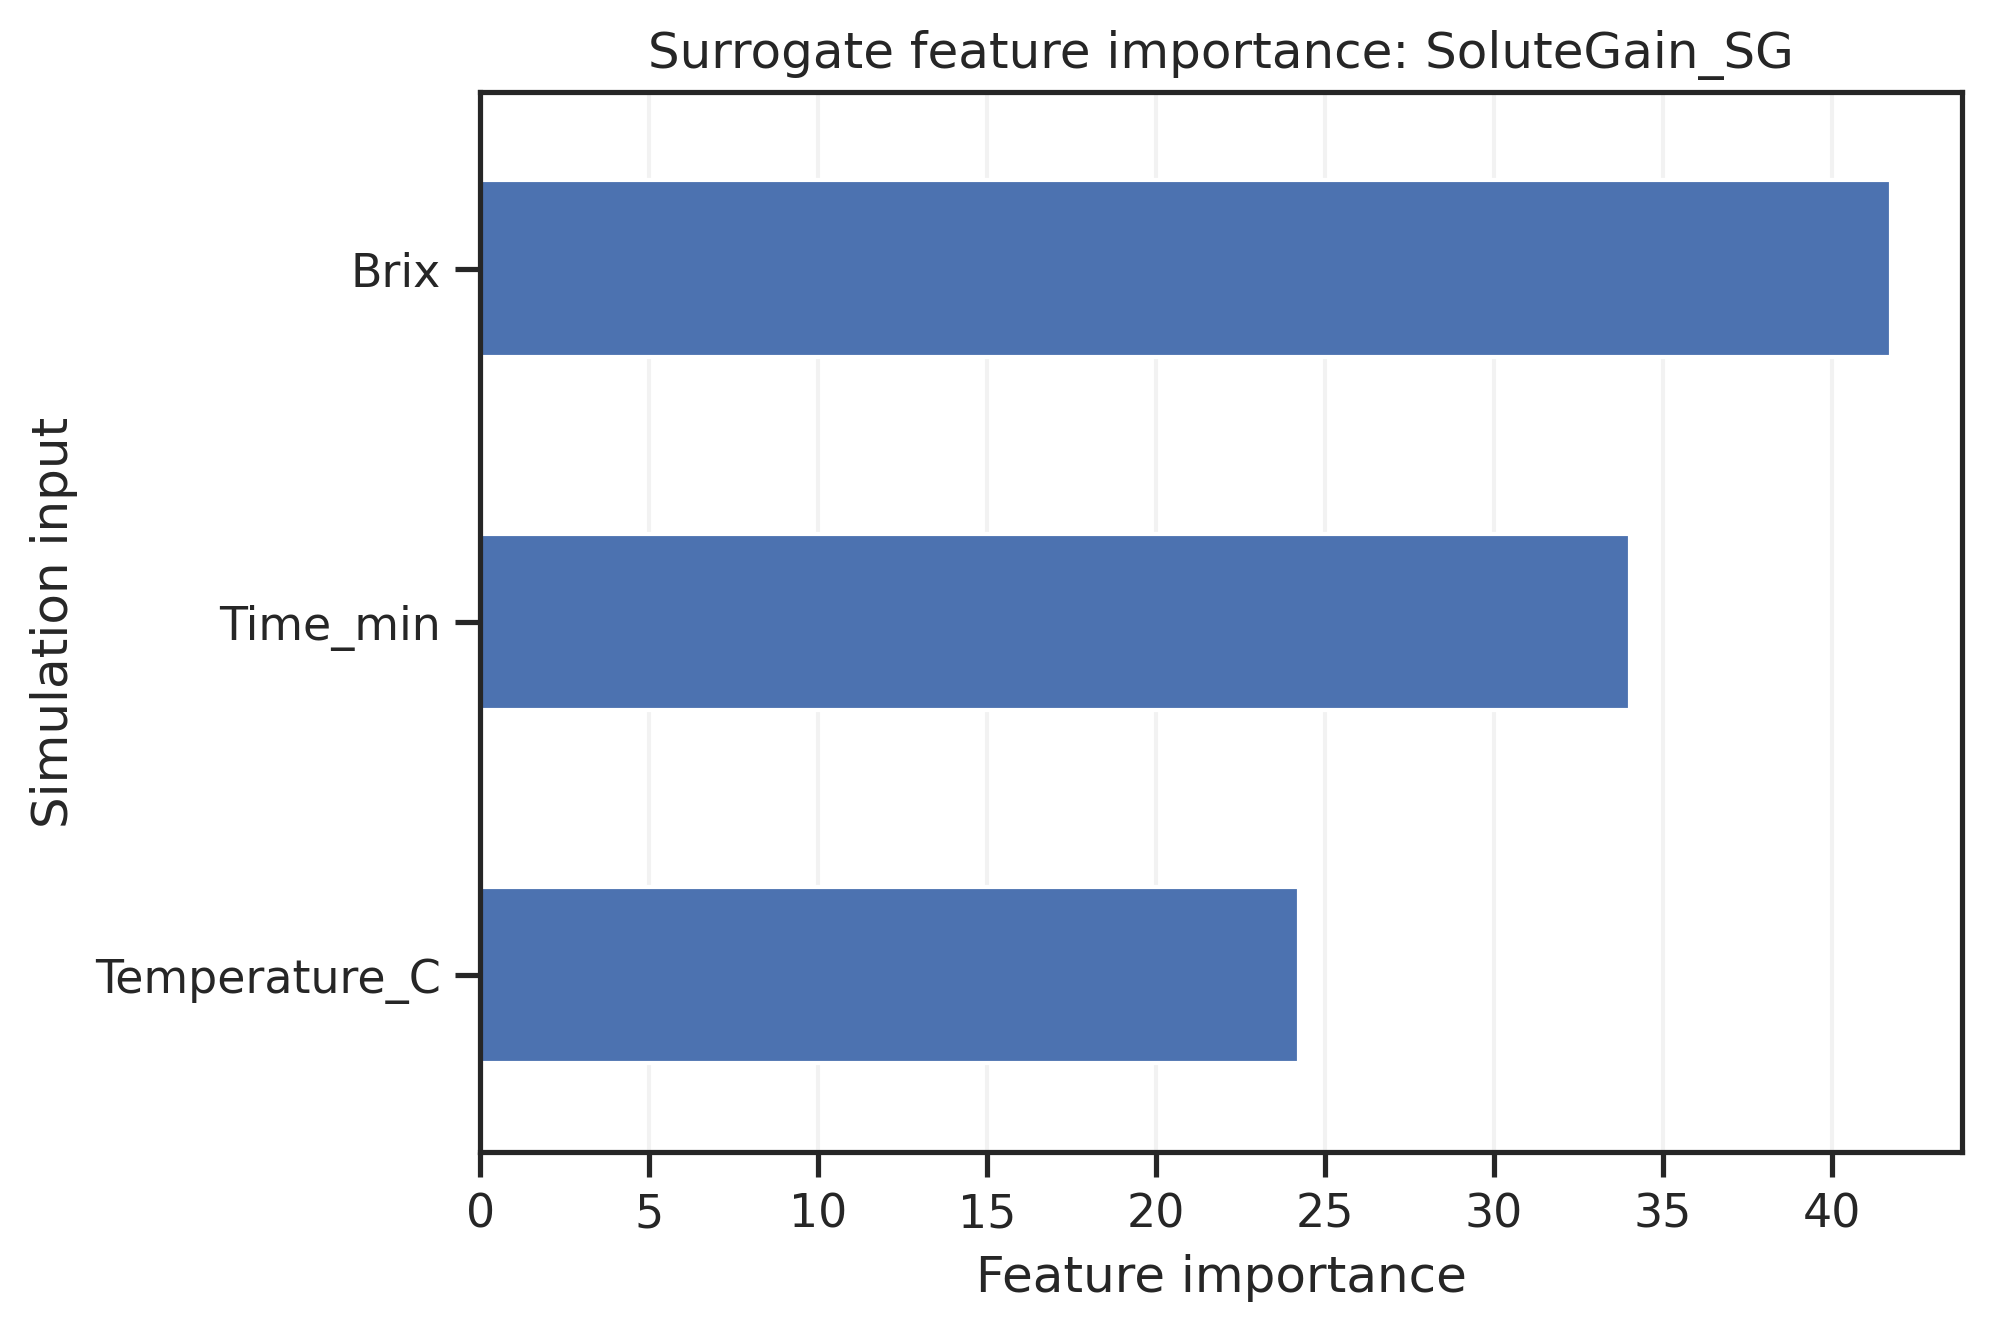

In [15]:
# step-14: Supporting feature importance

for target, model in final_models.items():

    if not hasattr(model, "feature_importances_"):
        print(f"{target}: feature importance unavailable.")
        continue

    importance = pd.Series(
        model.feature_importances_,
        index=FEATURES
    ).sort_values(ascending=True)

    fig, ax = plt.subplots(
        figsize=(6.8, 4.6),
        dpi=300
    )

    importance.plot(
        kind="barh",
        ax=ax
    )

    ax.set_xlabel("Feature importance")
    ax.set_ylabel("Simulation input")
    ax.set_title(
        f"Surrogate feature importance: {target}"
    )
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        FIG_DIR / f"feature_importance_{target}.png",
        bbox_inches="tight"
    )
    plt.show()
   


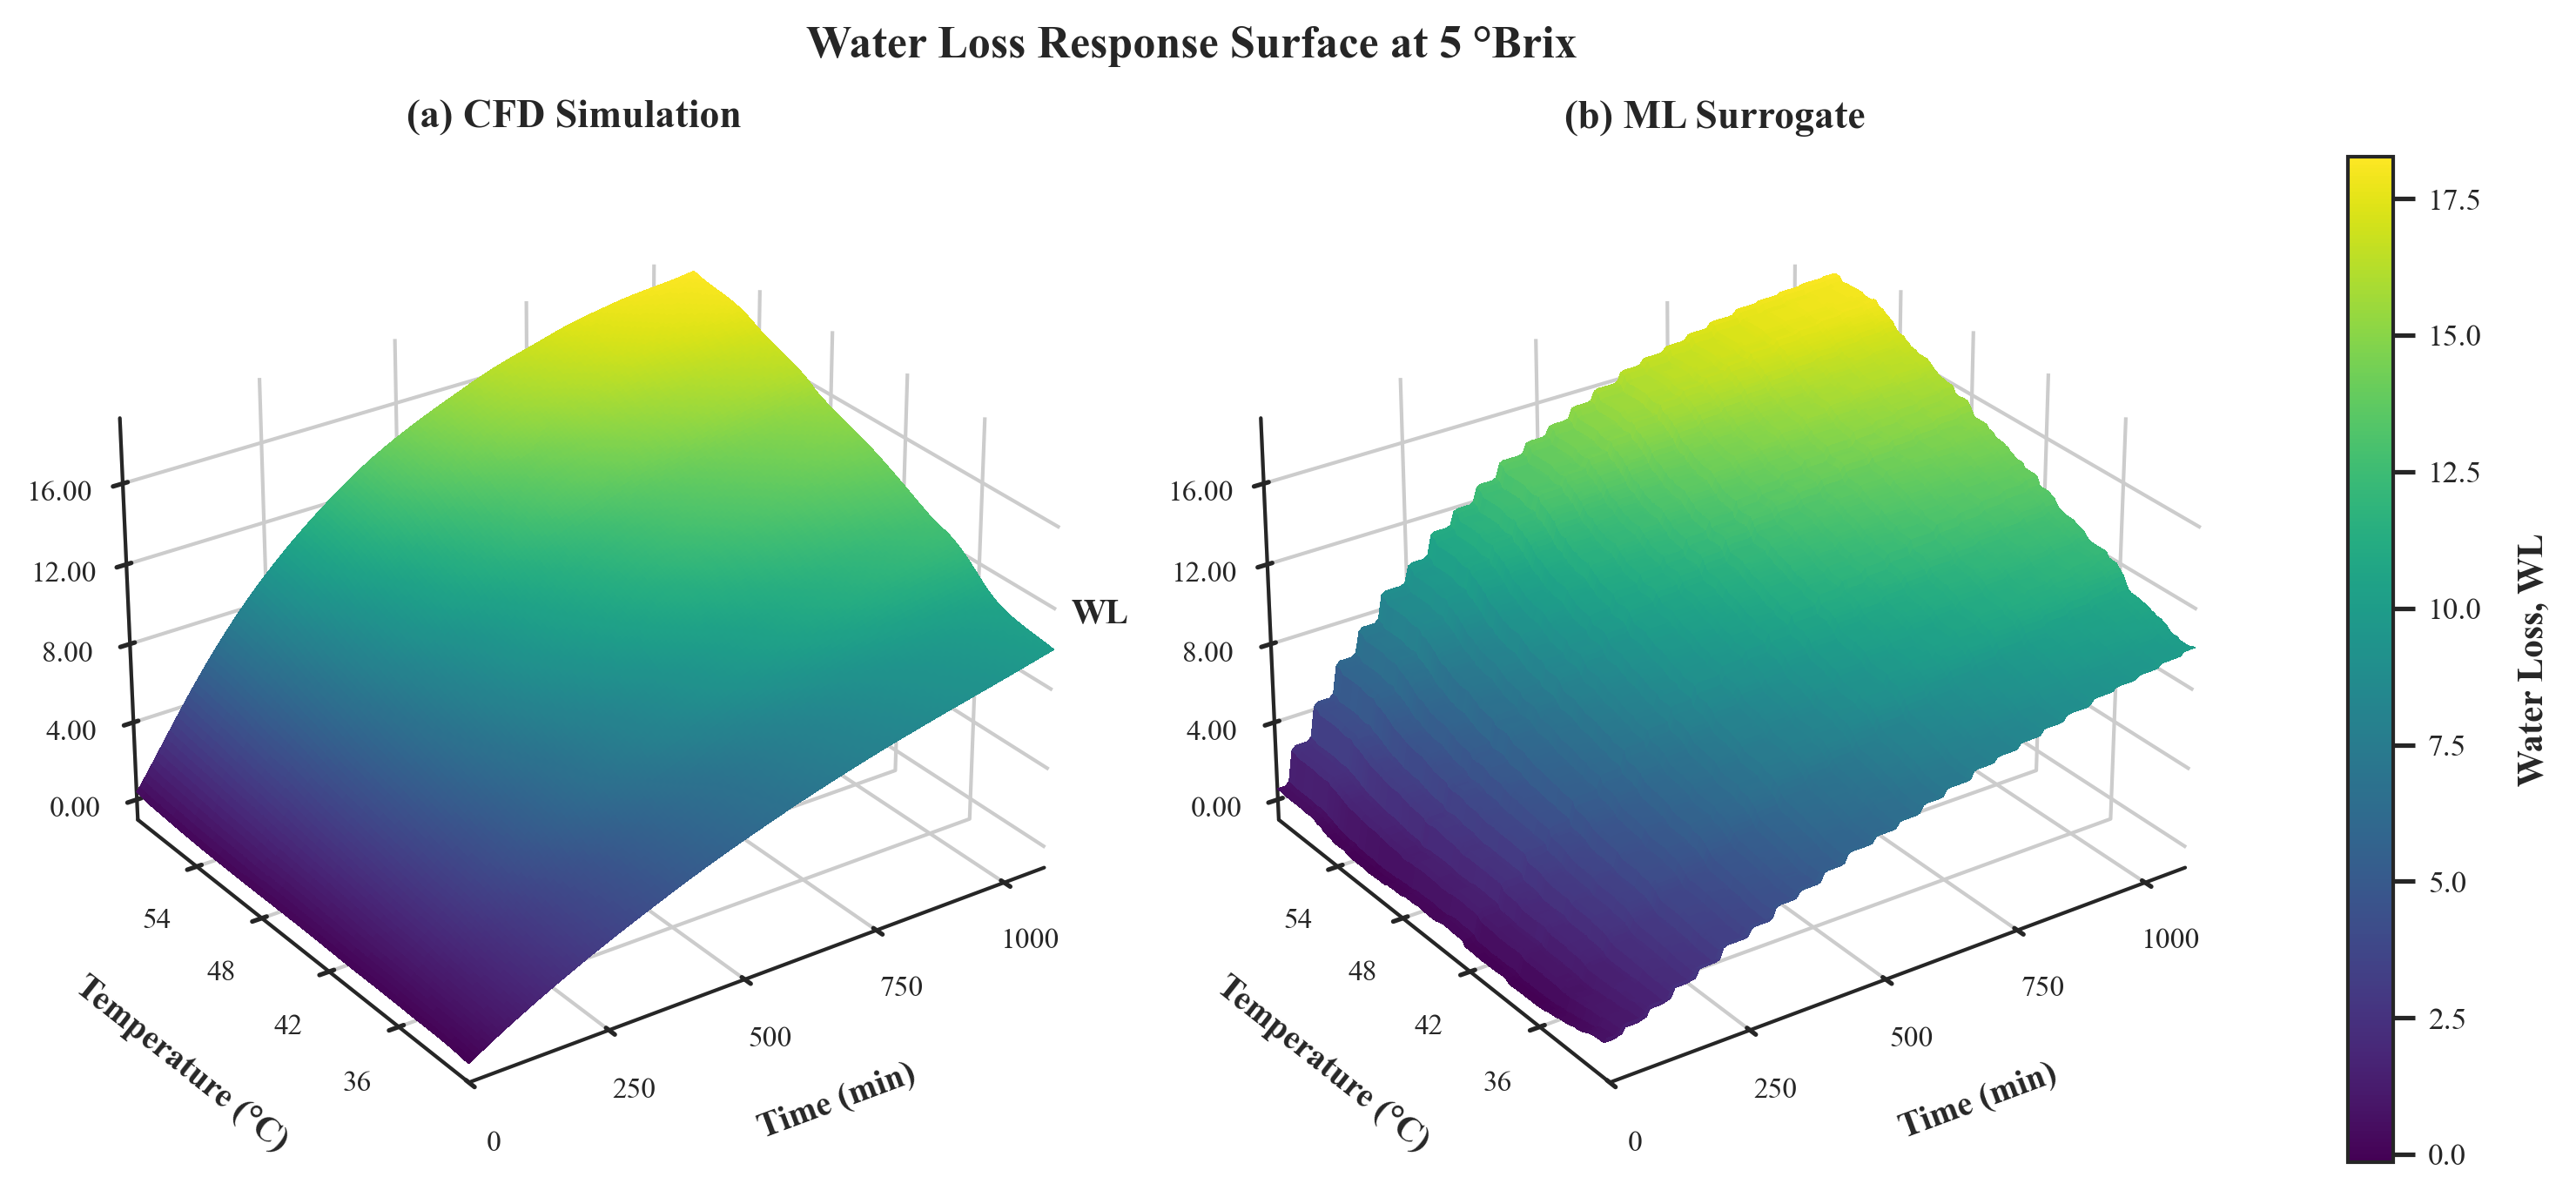

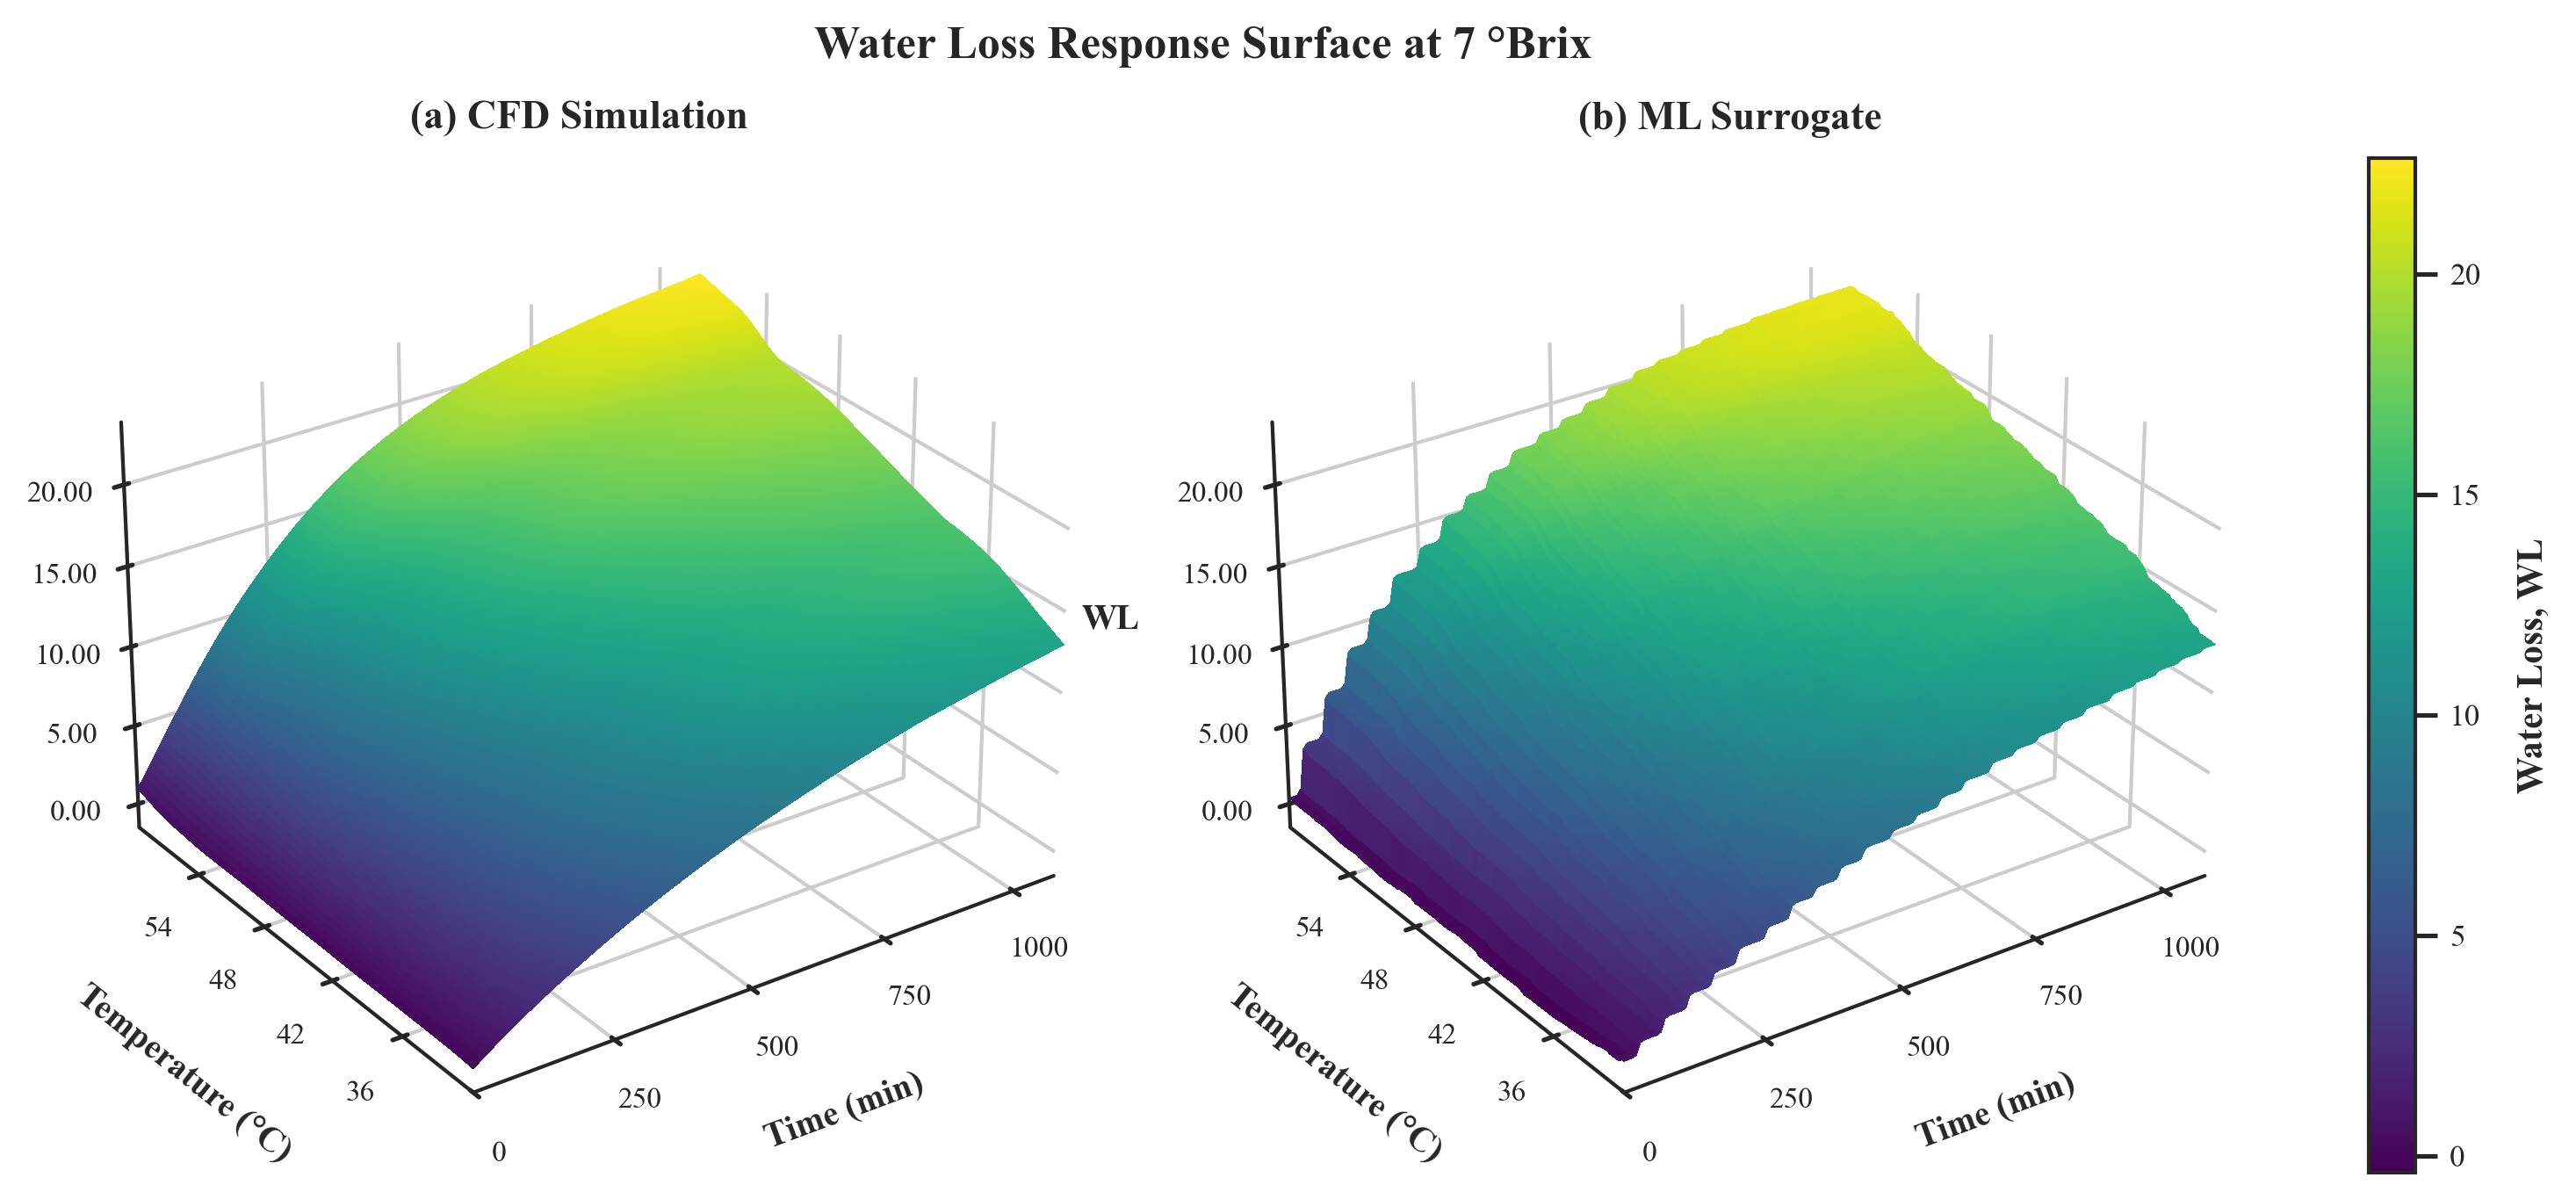

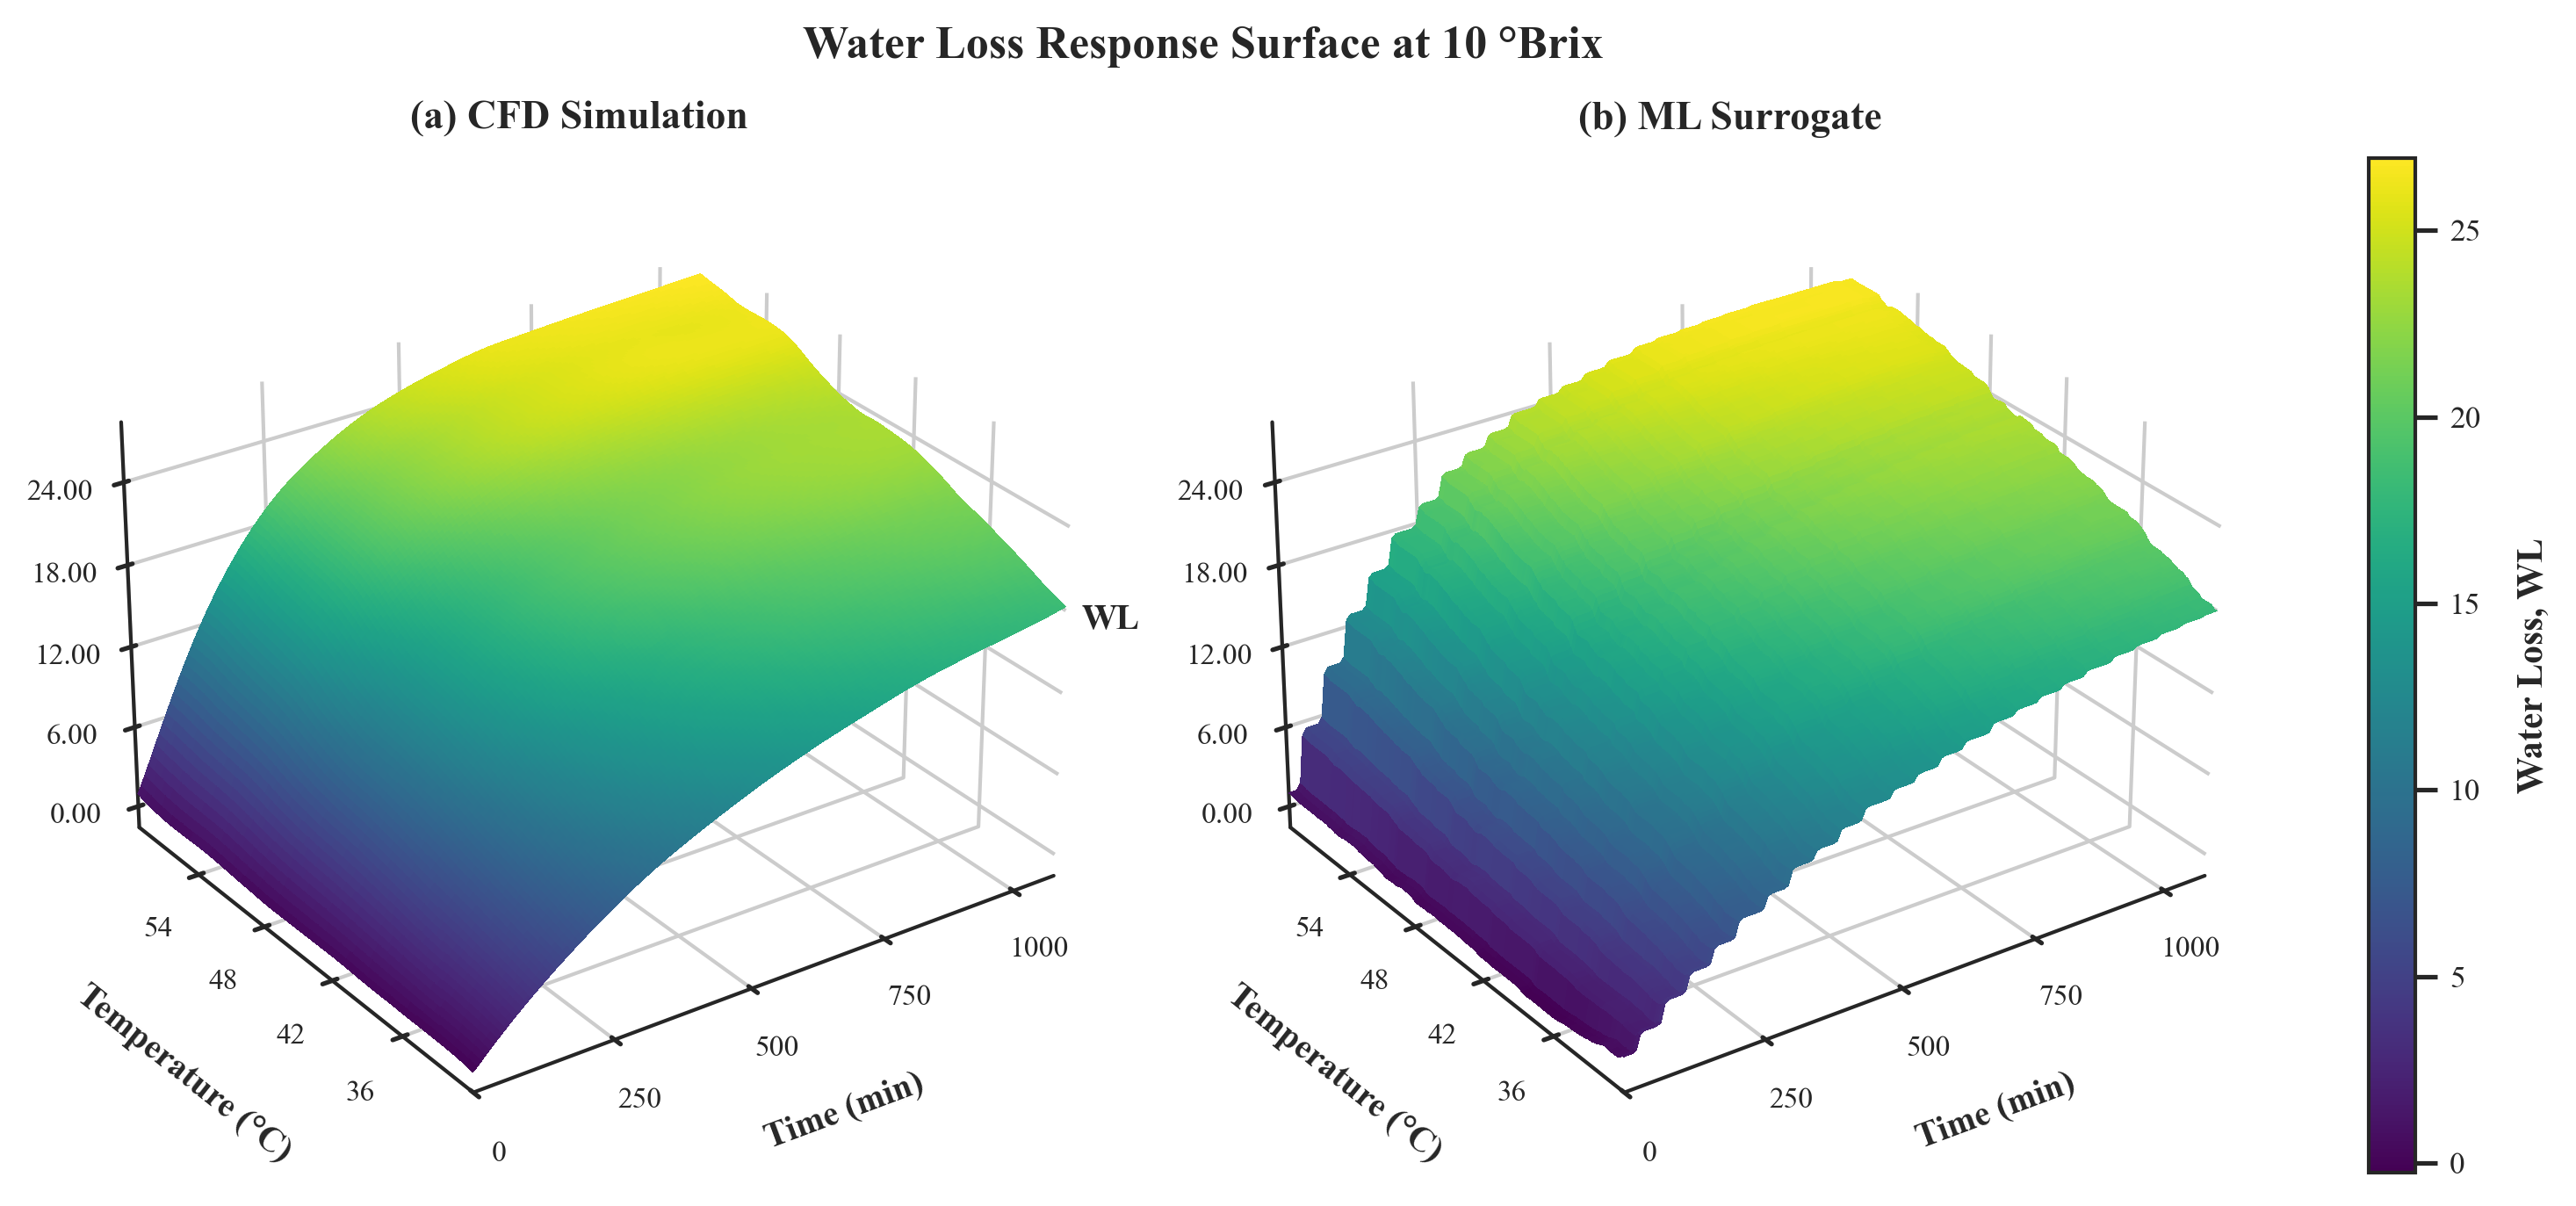

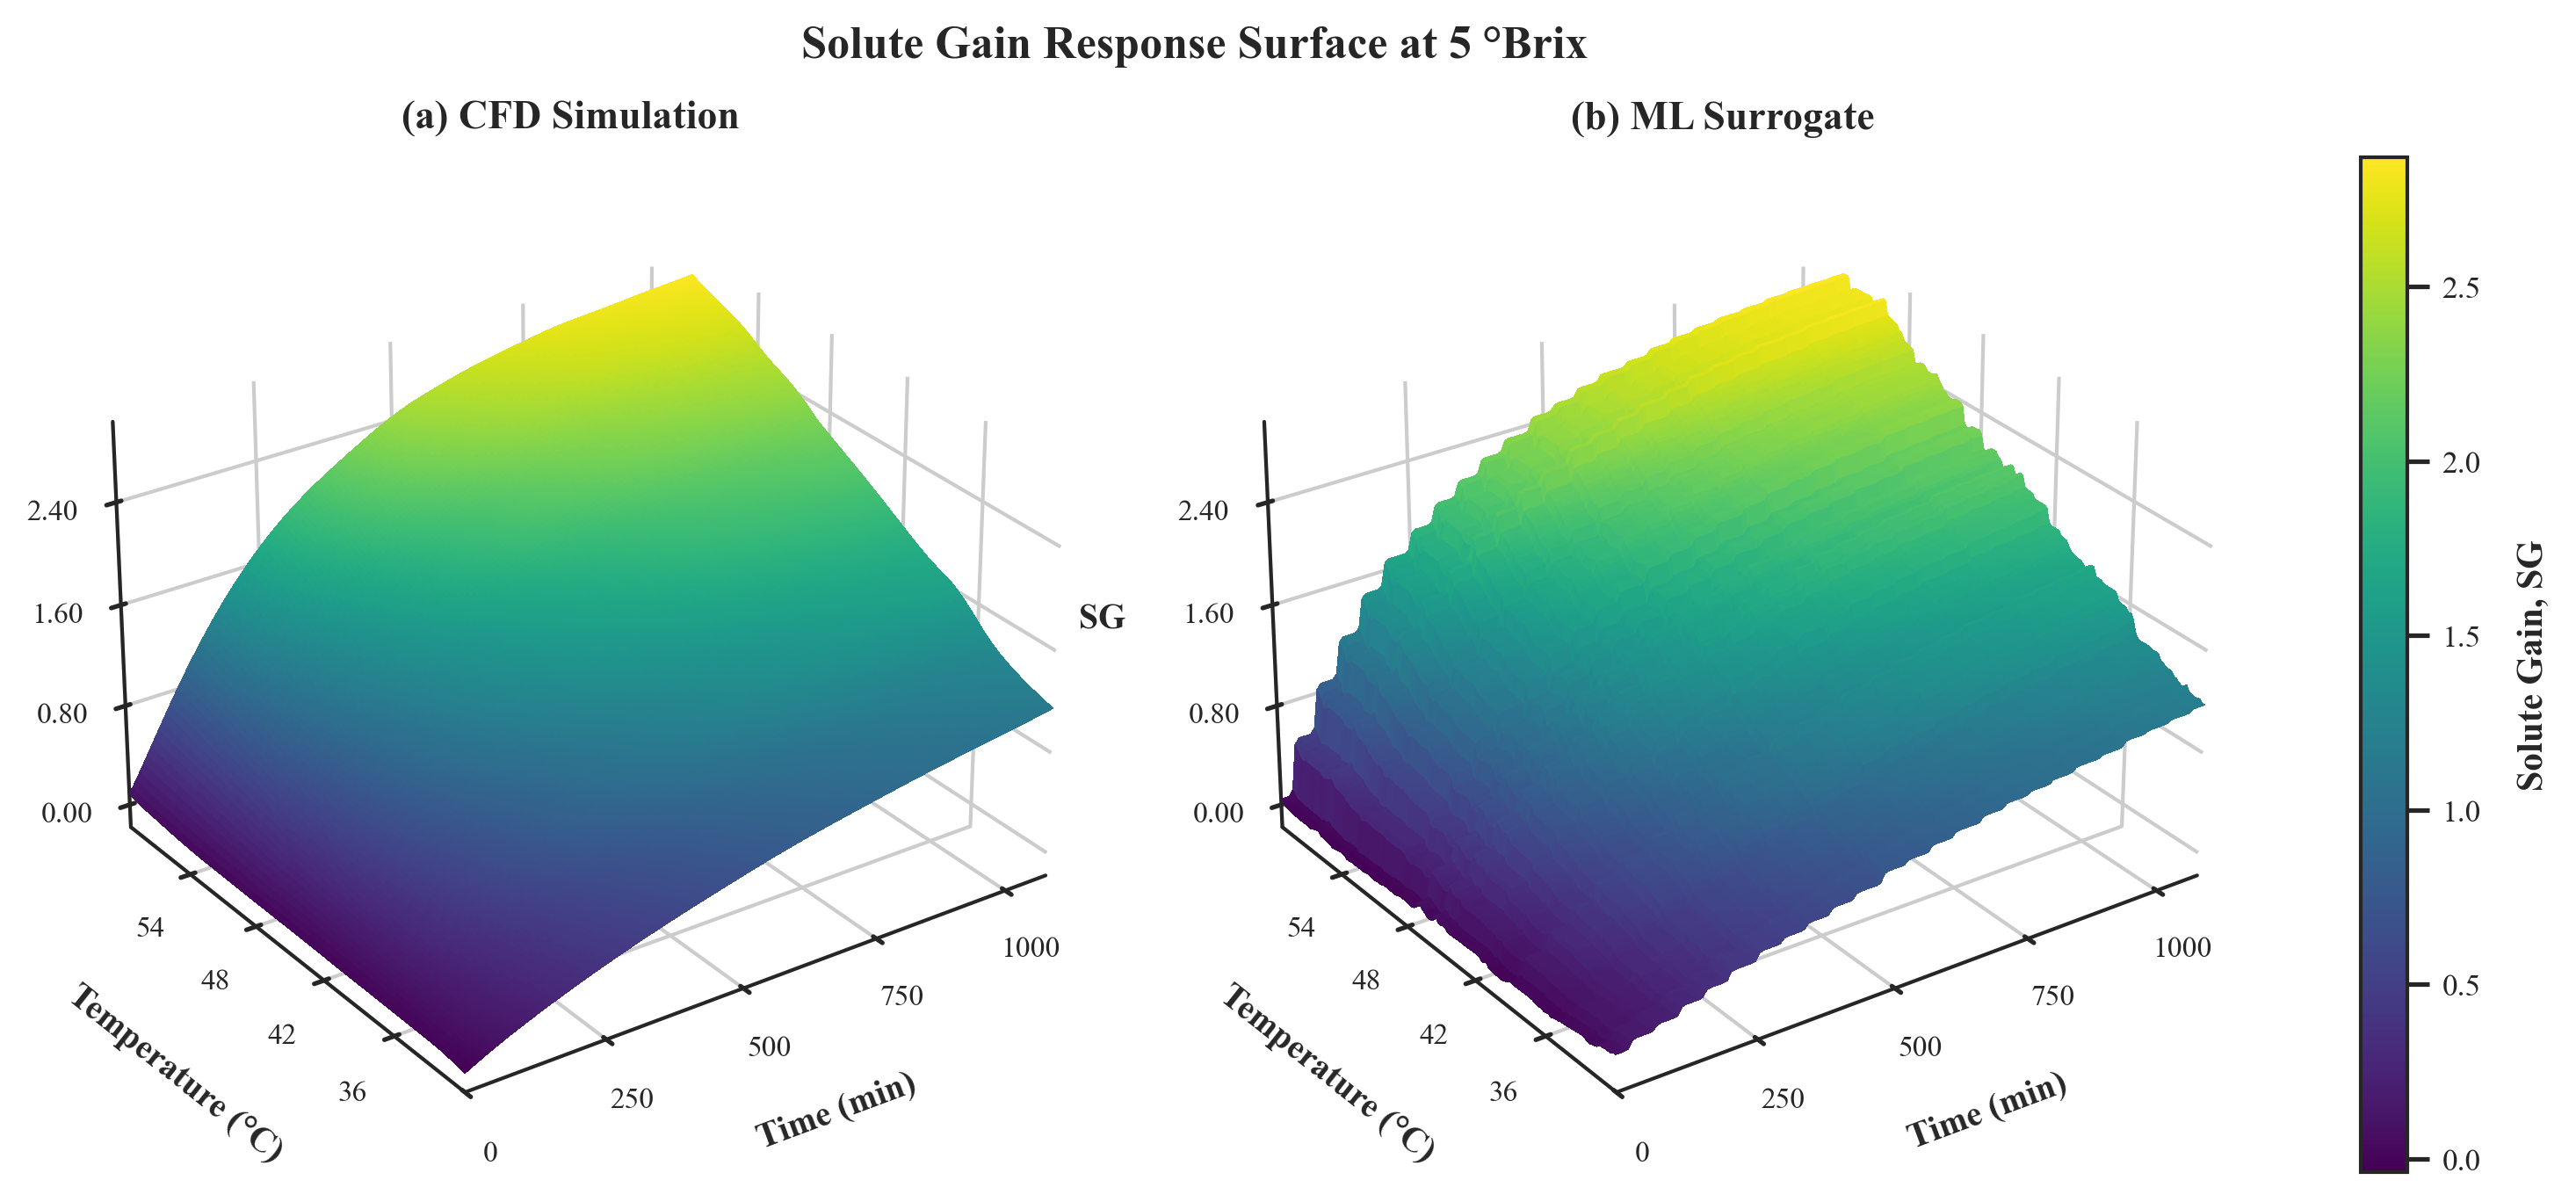

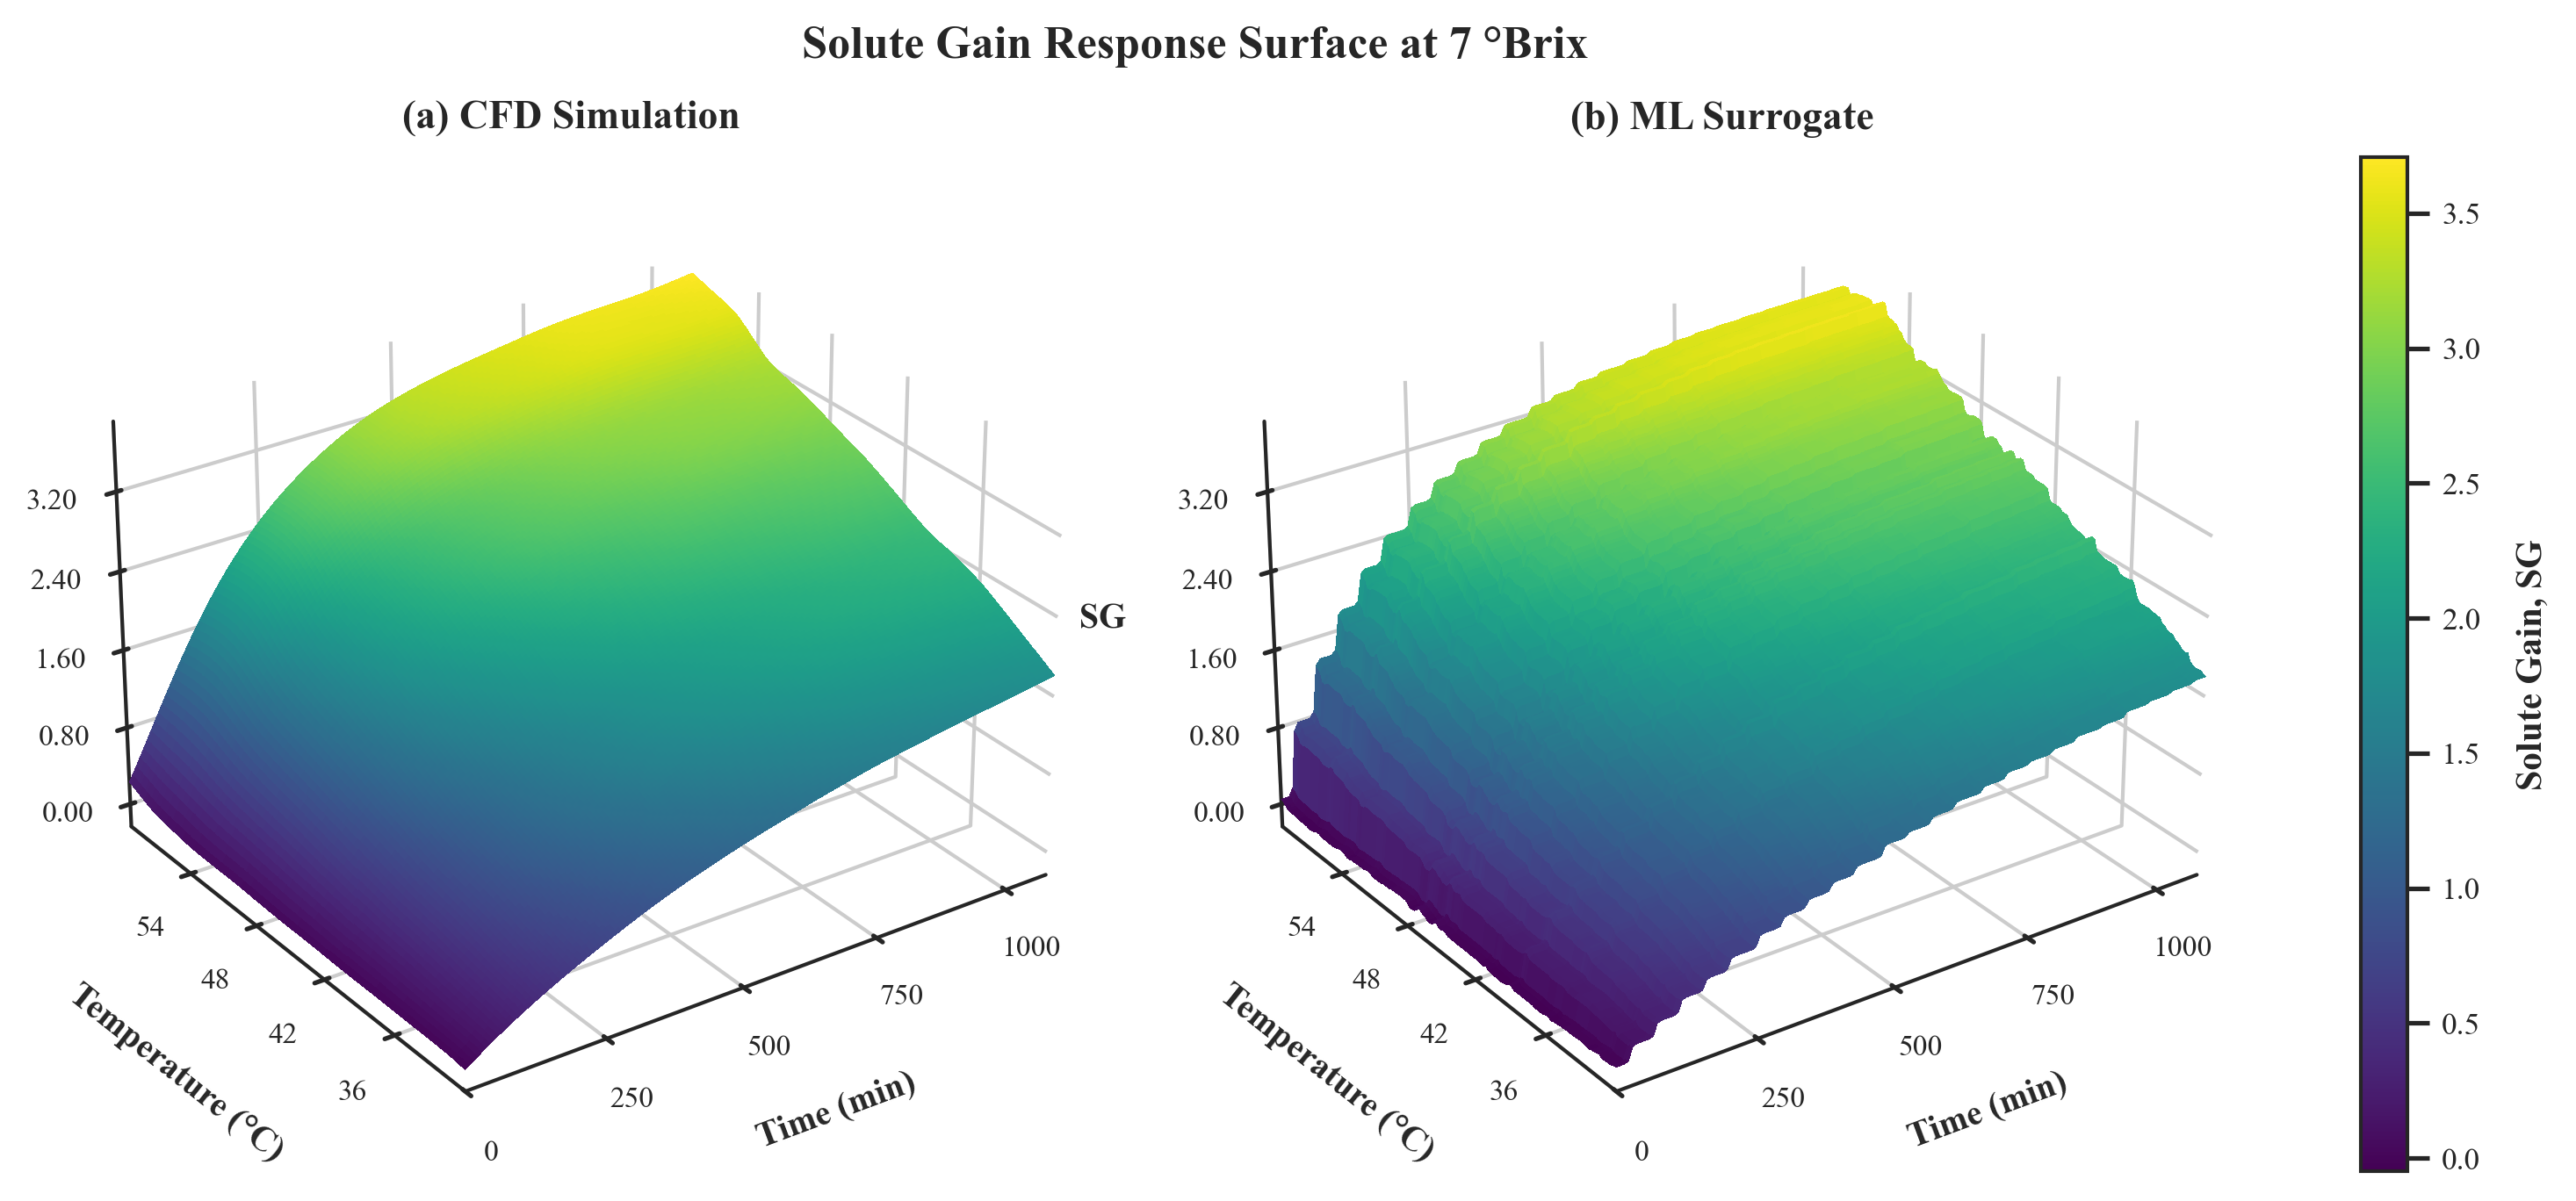

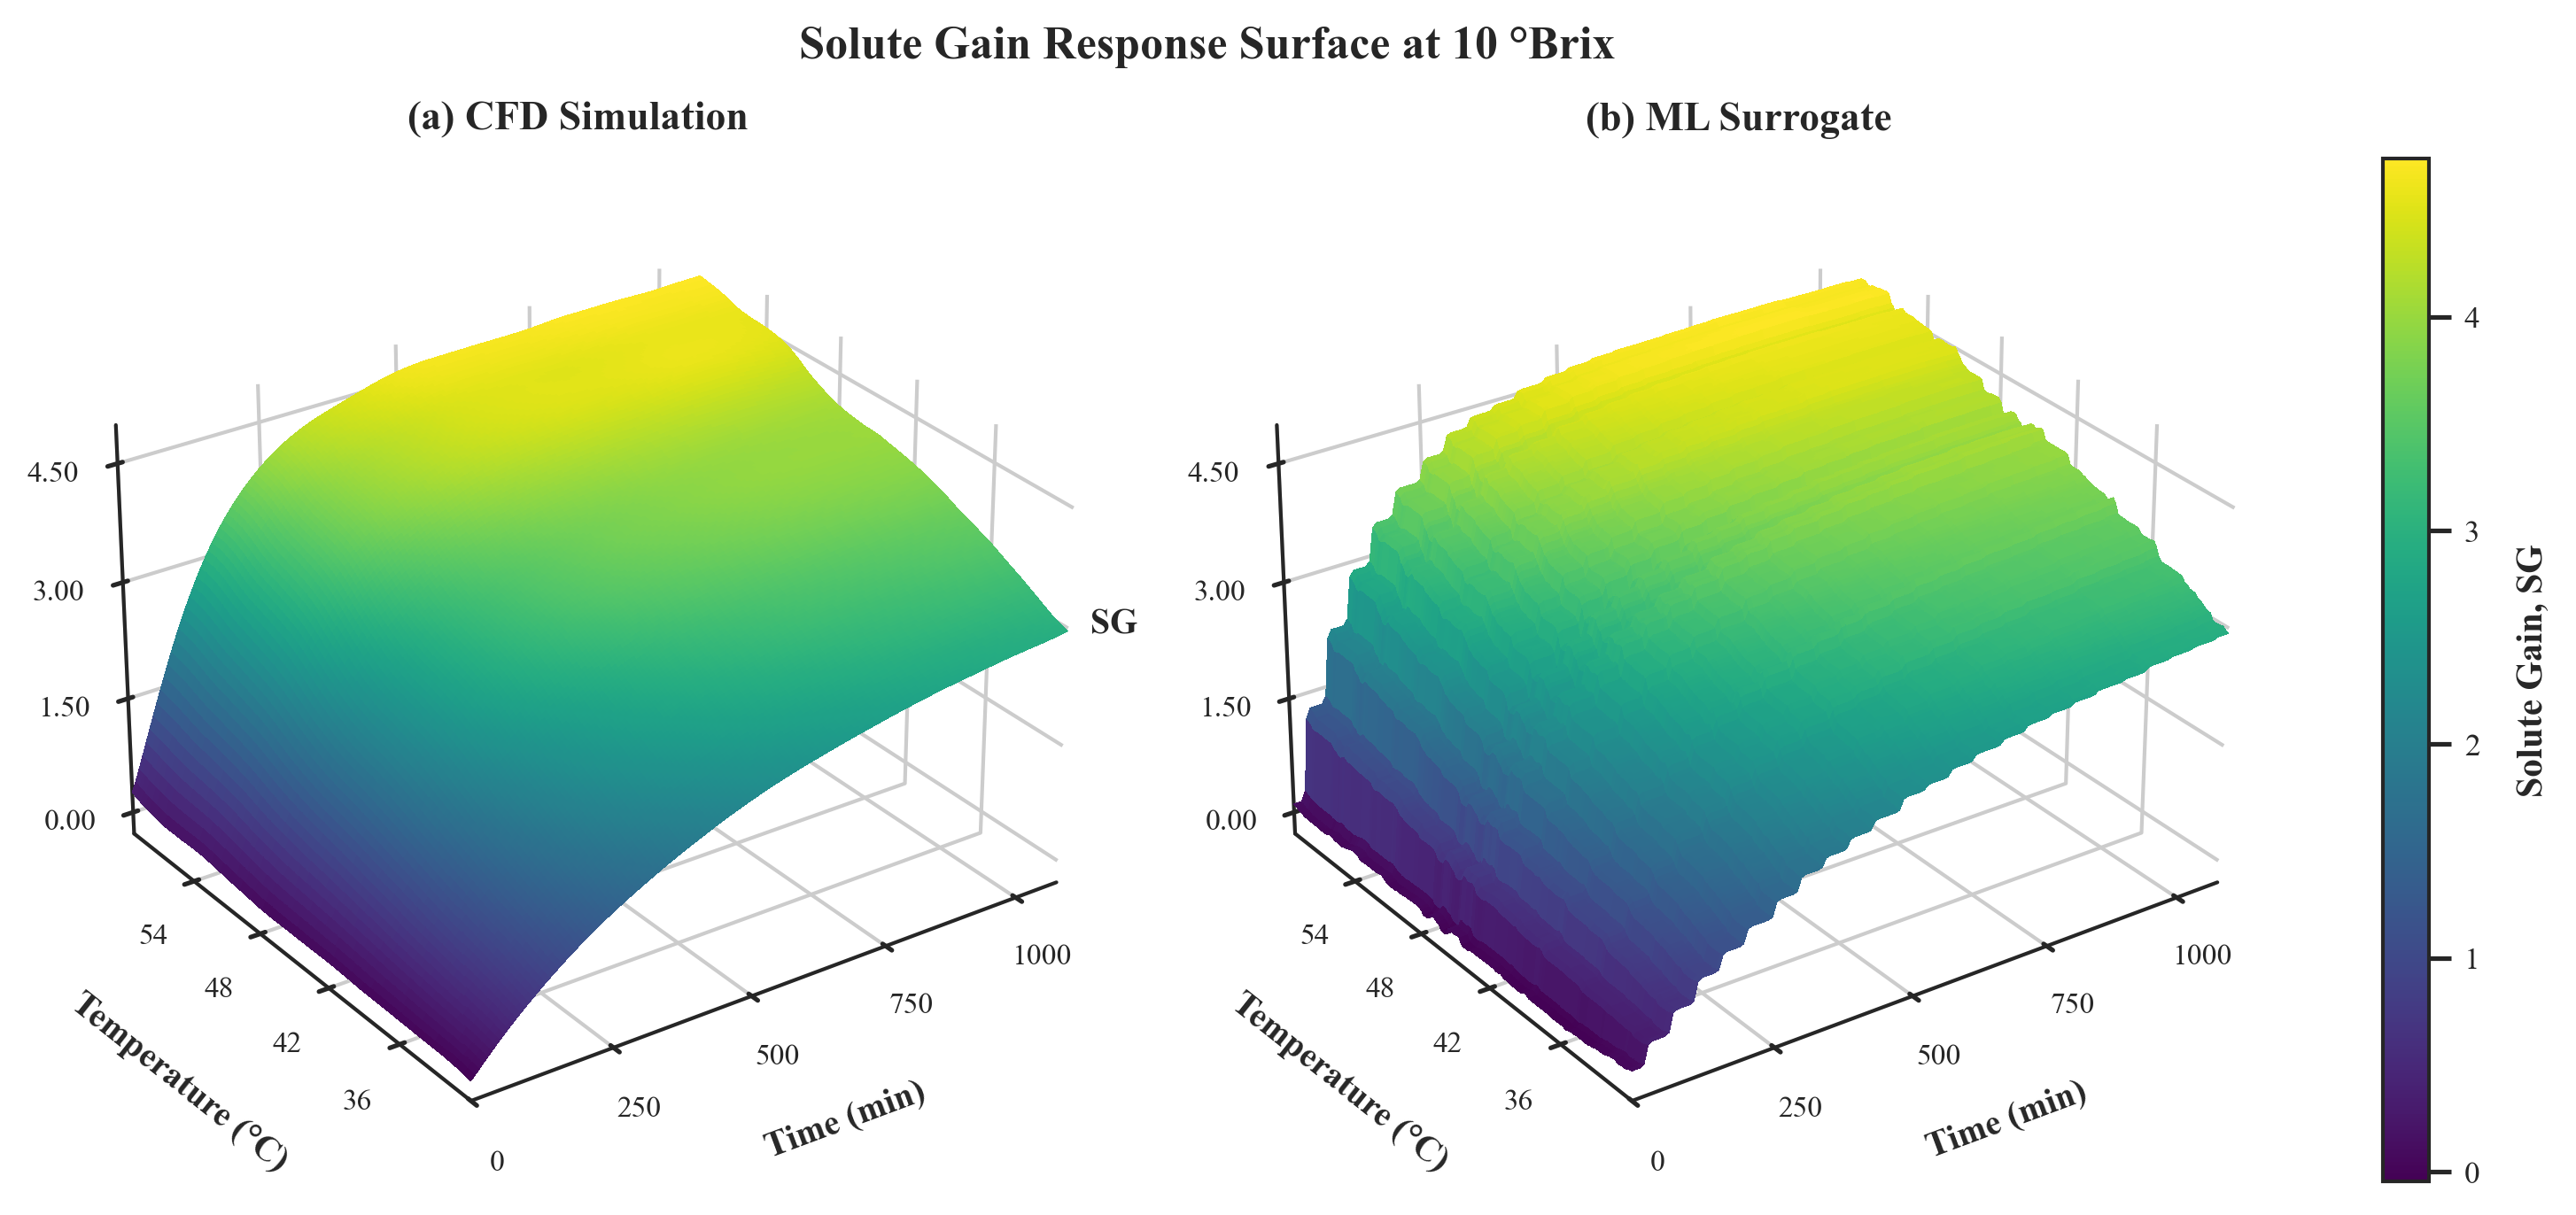

In [42]:

from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from scipy.interpolate import RBFInterpolator
from scipy.ndimage import gaussian_filter


plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 11,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
    }
)

GRID_POINTS = 150
RBF_SMOOTHING = 0.02
ACTUAL_SIGMA = 0.5
PRED_SIGMA = 0.5
SHARED_CMAP = "viridis"

SAVE_PNG = True
SAVE_PDF = True


def get_target_metadata(target):
    target_str = str(target).lower()
    if "wl" in target_str or "water" in target_str:
        return {"full": "Water Loss", "abbr": "WL"}
    elif "sg" in target_str or "solute" in target_str:
        return {"full": "Solute Gain", "abbr": "SG"}
    return {"full": str(target), "abbr": str(target)}


def plot_actual_predicted_single_brix(target, brix_val, grid_points=120):
    meta = get_target_metadata(target)


    temperature = pd.to_numeric(train_df["Temperature_C"], errors="coerce")
    brix = pd.to_numeric(train_df["Brix"], errors="coerce")
    target_value = pd.to_numeric(train_df[target], errors="coerce")
    time = pd.to_numeric(train_df[TIME_COL], errors="coerce")

    valid = (
        temperature.notna()
        & brix.notna()
        & target_value.notna()
        & time.notna()
    )

    df = train_df.loc[valid].copy()
    df["Temperature_C"] = temperature.loc[valid].to_numpy()
    df["Brix"] = brix.loc[valid].to_numpy()
    df[target] = target_value.loc[valid].to_numpy()
    df[TIME_COL] = time.loc[valid].to_numpy()

    time_min, time_max = df[TIME_COL].min(), df[TIME_COL].max()
    temp_min, temp_max = df["Temperature_C"].min(), df["Temperature_C"].max()

    time_grid = np.linspace(time_min, time_max, grid_points)
    temp_grid = np.linspace(temp_min, temp_max, grid_points)
    TIME_mesh, TEMP_mesh = np.meshgrid(time_grid, temp_grid)

    grid_xy = np.column_stack([TIME_mesh.ravel(), TEMP_mesh.ravel()])
    time_range = time_max - time_min
    temp_range = temp_max - temp_min

    def scale_xy(points):
        return np.column_stack([
            (points[:, 0] - time_min) / (time_range if time_range != 0 else 1.0),
            (points[:, 1] - temp_min) / (temp_range if temp_range != 0 else 1.0),
        ])

    grid_scaled = scale_xy(grid_xy)


    actual = df[
        np.isclose(df["Brix"], float(brix_val), atol=1e-8, rtol=0)
    ].copy()

    if actual.empty:
        raise ValueError(f"No data found at Brix = {brix_val:g}.")

    actual = actual.groupby([TIME_COL, "Temperature_C"], as_index=False)[
        target
    ].mean()
    points = actual[[TIME_COL, "Temperature_C"]].to_numpy(dtype=float)
    values = actual[target].to_numpy(dtype=float)

    rbf_actual = RBFInterpolator(
        scale_xy(points),
        values,
        kernel="thin_plate_spline",
        smoothing=RBF_SMOOTHING,
    )
    actual_surface = rbf_actual(grid_scaled).reshape(TIME_mesh.shape)
    actual_surface = np.nan_to_num(
        actual_surface,
        nan=np.nanmean(actual_surface),
        posinf=np.nanmax(actual_surface),
        neginf=np.nanmin(actual_surface),
    )
    actual_surface = gaussian_filter(actual_surface, sigma=ACTUAL_SIGMA)

    prediction_grid = pd.DataFrame({
        "Time_min": TIME_mesh.ravel(),
        "Temperature_C": TEMP_mesh.ravel(),
        "Brix": float(brix_val),
    })

    if TIME_COL != "Time_min":
        prediction_grid[TIME_COL] = TIME_mesh.ravel()

    predicted = final_models[target].predict(prediction_grid[FEATURES])
    predicted_surface = np.asarray(predicted, dtype=float).reshape(
        TIME_mesh.shape
    )
    predicted_surface = np.nan_to_num(
        predicted_surface,
        nan=np.nanmean(predicted_surface),
        posinf=np.nanmax(predicted_surface),
        neginf=np.nanmin(predicted_surface),
    )
    predicted_surface = gaussian_filter(predicted_surface, sigma=PRED_SIGMA)


    all_vals = np.concatenate([actual_surface.ravel(), predicted_surface.ravel()])
    vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.colormaps[SHARED_CMAP]

    z_pad = 0.05 * (vmax - vmin) if (vmax - vmin) != 0 else 0.1
    zmin, zmax = vmin - z_pad, vmax + z_pad


    fig = plt.figure(figsize=(11.5, 5.0), facecolor="white", dpi=300)
    gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.045], wspace=0.18)

    ax_actual = fig.add_subplot(gs[0, 0], projection="3d", computed_zorder=False)
    ax_actual.plot_surface(
        TIME_mesh,
        TEMP_mesh,
        actual_surface,
        cmap=cmap,
        norm=norm,
        rcount=grid_points,
        ccount=grid_points,
        linewidth=0,
        antialiased=False,
        shade=False,
        alpha=1.0,
        zorder=10,
    )

    ax_pred = fig.add_subplot(gs[0, 1], projection="3d", computed_zorder=False)
    ax_pred.plot_surface(
        TIME_mesh,
        TEMP_mesh,
        predicted_surface,
        cmap=cmap,
        norm=norm,
        rcount=grid_points,
        ccount=grid_points,
        linewidth=0,
        antialiased=False,
        shade=False,
        alpha=1.0,
        zorder=10,
    )

    subtitles = ["(a) CFD Simulation", "(b) ML Surrogate"]
    for ax, title in zip([ax_actual, ax_pred], subtitles):
        ax.set_xlim(time_min, time_max)
        ax.set_ylim(temp_min, temp_max)
        ax.set_zlim(zmin, zmax)

        ax.set_xlabel("Time (min)", labelpad=7, fontsize=9.5, fontweight="bold")
        ax.set_ylabel("Temperature (°C)", labelpad=7, fontsize=9.5, fontweight="bold")
        ax.set_zlabel(meta["abbr"], labelpad=6, fontsize=9.5, fontweight="bold")

        ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
        ax.view_init(elev=28, azim=-125)

        try:
            ax.set_box_aspect((1.15, 1.0, 0.75))
        except AttributeError:
            pass

        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.zaxis.set_major_locator(MaxNLocator(5))

        ax.xaxis.set_major_formatter(FormatStrFormatter("%.0f"))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))
        ax.zaxis.set_major_formatter(FormatStrFormatter("%.2f"))

        ax.tick_params(labelsize=8, pad=2)

        ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        ax.grid(True, color="#D1D5DB", linewidth=0.5, linestyle=":", alpha=0.8)

    cax = fig.add_subplot(gs[0, -1])
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(all_vals)
    cbar = fig.colorbar(mappable, cax=cax, orientation="vertical")
    
    cbar.set_label(f"{meta['full']}, {meta['abbr']}", fontsize=10, fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=8.5)

    fig.suptitle(
        f"{meta['full']} Response Surface at {brix_val:g} °Brix",
        fontsize=12.5,
        fontweight="bold",
        y=0.98,
    )

    fig_dir = Path(FIG_DIR)
    fig_dir.mkdir(parents=True, exist_ok=True)

    safe_target = meta["full"].lower().replace(" ", "_")
    png_path = fig_dir / f"surface_paired_{safe_target}_brix{brix_val:g}.png"
    pdf_path = fig_dir / f"surface_paired_{safe_target}_brix{brix_val:g}.pdf"

    if SAVE_PNG:
        fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
    if SAVE_PDF:
        fig.savefig(pdf_path, format="pdf", bbox_inches="tight", facecolor="white")

    plt.show()
    plt.close(fig)


brix_values = sorted(train_df["Brix"].dropna().unique())

for target in TARGETS:
    for b_val in brix_values:
        plot_actual_predicted_single_brix(
            target=target, brix_val=b_val, grid_points=GRID_POINTS
        )

# The End


